### Cleaning 
* Dealing with outliers
First we find outliers using Quartile method, then we change those values as null and then we treat them as null values .
Second Check for duplicated rows, if have any remove with `'DATA.dropduplicates()'`.

We don't do the outlier test for age because the to young or to old people are also objects of this matter .

In [1]:
import numpy as np
import pandas as pd
# data_1 = pd.read_csv('filename.csv')
continuous_columns = ['oldpeak','chol','thalach','trestbps']
data_1 = pd.read_csv('filename.csv') # its for faster reading and testing 
print(continuous_columns)
for i in continuous_columns :
    print(i)
    Q1 = data_1[i].quantile(.25)
    Q3 = data_1[i].quantile(.75)
    IRQ = 1.5 * (Q3 - Q1)
    print("IRQ", Q1 -IRQ,Q3+IRQ)
    data_1.loc[(data_1[i] < Q1 - IRQ) | (data_1[i] > Q3 + IRQ),i] = pd.NA
data_1.info()
print(data_1.duplicated().sum())
print(data_1['ca'].unique())


['oldpeak', 'chol', 'thalach', 'trestbps']
oldpeak


NameError: name 'data_1' is not defined

* Replace or remove values 
In this project we use the median replacement method for our data .

There is several Method to treat outliers and null (missing) values . for more infromation https://www.neenopal.com/dealing-with-outliers-and-missing-values-in-a-dataset.html.

**Methods of dealing with null**
we use 3 methods :
* fill with median 
* fill with mean 
* remove

In [2]:
data_mean = data_1.copy(deep=True)
data_remove = data_1.copy(deep=True)

for i in data_1.keys():
    data_1[i].fillna(data_1[i].median(),inplace=True)

data_1.info()
data_1.describe()
print(data_1)

NameError: name 'data_1' is not defined

In [3]:
for i in data_mean.keys():
    if i == 'ca' or i == 'thal':
        data_mean[i].fillna(round(data_mean[i].median()),inplace=True)
        continue
    data_mean[i].fillna(data_mean[i].mean(),inplace=True)
data_mean = data_mean.drop('disease',axis=1)
data_mean.info()
data_mean.describe()
print(data_mean['thal'].unique())

NameError: name 'data_mean' is not defined

In [4]:
data_remove = data_remove.dropna().reset_index(drop=True)
data_target_remove = data_remove['disease']
data_remove.drop('disease',axis=1,inplace=True)
data_remove.info()
print(data_target_remove)

NameError: name 'data_remove' is not defined

For better understaing the data, We fix the names of variables that has class or they are categorial with meaning (ordered or nominal).
All changes are based on information from (https://archive.ics.uci.edu/dataset/45/heart+disease). 


Remember, If you change type data before cleaning it might be harder to fix the missing data or outliers, so we take a copy from data to apply those changes to second copy and use that for correlations and filling missing values .

In [5]:
data_2 = data_1.copy(deep=True)#making a copy because these changes , will change the objects type . we need this copy for second part.
data_1['sex'] = data_1.sex.replace({1: "Male", 0: "Female"})
data_1['cp'] = data_1.cp.replace({1: "typical_angina", 2: "atypical_angina", 3:"non-anginal pain",4: "asymtomatic"})
data_1['exang'] = data_1.exang.replace({1: "Yes", 0: "No"})
data_1['fbs'] = data_1.fbs.replace({1: "True", 0: "False"})
data_1['slope'] = data_1.slope.replace({1: "upsloping", 2: "flat",3:"downsloping"})
data_1['thal'] = data_1.thal.replace({6: "fixed_defect", 7: "reversable_defect", 3:"normal"})
data_1['restecg'] = data_1.thal.replace({0: "normal", 1: "abnormality", 2:"definitive"})
data_1['ca'] = data_1.ca.replace({0: "One", 1: "Two", 2:"Three",3: "Four"})

print(data_1)
print(data_remove['thal'].unique())

NameError: name 'data_1' is not defined

**Deciding on the Target values**


Base on the information from https://www.heart.org/en/health-topics/heart-failure/what-is-heart-failure/classes-of-heart-failure, We can change target values to understand the data better .
we split target to 5 phase: 
* N   Not ill = 0 
* A	At high risk for heart failure but without structural heart disease or symptoms of heart failure. = 1
* B	Structural heart disease but without signs or symptoms of heart failure. = 2
* C	Structural heart disease with prior or current symptoms of heart failure. = 3
* D	Refractory heart failure requiring specialized interventions.= 4

In [6]:
data_1['disease'] = data_1.disease.replace({0:'N',1:'A',2:'B',3:'C',4:'D'})
print(data_1)
print(data_2)

NameError: name 'data_1' is not defined

### Analyzing Data 
#### Data Atrributes explanations
**CP: Chest pain type**
* Typical Angina : This is often one of the first manifestations or warning signs of underlying coronary disease,substernal chest pain precipitated by physical exertion or emotional stress and relieved with rest or nitroglycerin.
* Atypical Angina :is a type of chest pain that only has some of the features of typical chest pain. It may also include chest pain that: Lasts for a few seconds, then quickly subsides. Worsens when your body is in certain positions.might showing the disease
* Non-anginal pain :Nonanginal chest pain, which doctors may also call noncardiac chest pain, refers to pain a person without heart disease may feel behind the breast bone.
* Asymptomatic : Asymptomatic chest pain is a condition where a person experiences chest pain without any other symptoms.

**Trestbps**
* The person's resting blood pressure


**Chol**
* A cholesterol test looks at the levels of cholesterol and other fats in your blood


**Fbs**
* Fasting blood sugar (FBS) measures blood glucose after you have not eaten for at least 8 hours


**restecg**:
Resting electrocardiogram (ECG) is a non-invasive test that measures the electrical activity of your heart while you are at rest
* Normal: Indicates a normal resting ECG result.
* ST-T wave abnormality: This may include ST elevation or depression, T-wave abnormalities, or both.
* Probable or definite left ventricular hypertrophy: This suggests an enlargement of the left ventricle of the heart.


**thalach**
* maximum heart rate achieved


**exang**: 
exercise-induced angina, Exercise-induced angina specifically refers to angina that is triggered or worsened by physical exertion or exercise.
* No :Absence of exercise-induced angina.
* Yes :Presence of exercise-induced angina.

**oldpeak**: refers to the ST depression induced by exercise relative to rest,
The "oldpeak" variable is a numerical measure that quantifies the amount of ST depression observed during an exercise test.

**slope**:"slope" often refers to the slope of the peak exercise ST segment,
The "slope" variable typically represents the slope of the ST segment during exercise testing, and it is often categorical, with values indicating different patterns
* Upsloping : Indicates a positive slope of the ST segment during exercise, which might be considered a less severe abnormality.
* Flat : Indicates a flat or horizontal ST segment during exercise.
* Downsloping : Indicates a negative slope of the ST segment during exercise, which might be considered a more severe abnormality.

**ca**:"ca" typically refers to the number of major vessels colored by fluoroscopy during cardiac catheterization. It is often used as a predictor or feature in models predicting the presence or absence of heart disease.
* 0: No major vessels colored by fluoroscopy (indicating no significant stenosis or blockage).
* 1: One major vessel colored.
* 2: Two major vessels colored.
* 3: Three major vessels colored.

**thal**:"thal" typically refers to thallium stress test results or nuclear stress test results. Thallium is a radioactive substance that can be used in medical imaging to evaluate blood flow to the heart muscle.
* Normal: Indicates a normal thallium stress test result.
* Fixed defect: Suggests a fixed defect in the distribution of thallium, which may indicate a region of the heart with reduced blood flow both during stress and at rest.
* Reversible defect : Suggests a reversible defect in the distribution of thallium, which may indicate an area of the heart with reduced blood flow during stress but normal blood flow at rest.




**Distribution of The Data**

In order to understand the data better ,first we need to see the distribution of the data .

after this phase we start to show the relations using tools like `matplotlib.pyplot and seaborn`
We first take the continus variables , then we plot the categorical variables .


In [7]:
data_1.info()
import matplotlib.pyplot as plt
import seaborn as sns
data_1['age'] = data_1['age'].astype('float')
data_1['ca'] = data_1['ca'].astype('object')
A = data_1.select_dtypes('int')
for i in A:
    data_1[i] = data_1[i].astype('int')
plt.figure(figsize=(30, 20))
for i , col in enumerate(data_1.select_dtypes('float'),1):#continus variable distribution
    plt.subplot(4,4,i)
    histplot = sns.histplot(data_1[col],kde=True)


NameError: name 'data_1' is not defined

In [8]:
object_columns = data_1.select_dtypes(include='object').columns
a = len(object_columns)
b = 0
print(a % 2)
if a % 2 != 0:
    a = a//2
    b = a + 1
else : 
    a = a//2 
    b = a 
print(a,b)
plt.figure(figsize=(30, 20))
for i , col in enumerate(data_1.select_dtypes('object'),1):#continus variable distribution
    if i > a + 1  :
        continue
    plt.subplot(4,4,i)
    histplot = sns.histplot(data_1[col])
    total = 0
    for i in histplot.patches:
        total = total + i.get_height()
    for i in histplot.patches:
        histplot.text(i.get_x()+.2,i.get_y()+5,str(round((i.get_height()/total)*100, 2))+'%', fontsize=14,color='white', weight = 'bold')
plt.show()
plt.figure(figsize = (30, 15))
for i , col in enumerate(data_1.select_dtypes('object'),1):#continus variable distribution
    if i < b + 1 :
        continue
    plt.subplot(4,4,i)
    histplot = sns.histplot(data_1[col])
    total = 0
    for i in histplot.patches:
        total = total + i.get_height()
    for i in histplot.patches:
        histplot.text(i.get_x(),i.get_y()+5,str(round((i.get_height()/total)*100, 2))+'%', fontsize=12,color='white', weight = 'bold',va='center')
plt.show()


NameError: name 'data_1' is not defined

In [9]:
# for i in data_1.keys():
#     print (data_1[i].unique(),f'{i}')
#     print (data_remove[i].unique(),f'{i}')
#     print (data_mean[i].unique(),f'{i}')

data_1.info()
data_2.info()
data_mean.info()
data_remove.info()



NameError: name 'data_1' is not defined

## Association Rules Mining

Association rules mining is a data mining technique used to discover interesting patterns, relationships, or associations in large datasets. It is particularly useful in market basket analysis to identify relationships between different products that are frequently purchased together.

### Key Concepts:

- **Itemset:**
  - An itemset is a collection of one or more items, such as products in a store.

- **Support:**
  - Support measures the frequency of occurrence of an itemset in the dataset.

- **Confidence:**
  - Confidence measures the likelihood that an association rule is true.

- **Lift:**
  - Lift measures the strength of an association rule over random chance.

- **Association Rule:**
  - An association rule is an implication expression of the form "X implies Y," where X and Y are itemsets.



### Apriori Algorithm:

The Apriori algorithm is commonly used for association rule mining. It works by iteratively finding frequent itemsets of increasing size.

**How to use it**
In order to use apriori algorithm ,we need data to be false or true (0, 1) ,to achieve this we need to analyzie the data and decide how to map the each amount to binary .
so we start to see the relation by correlations matrix and using that inorder to analyzie and decide .

<Axes: >

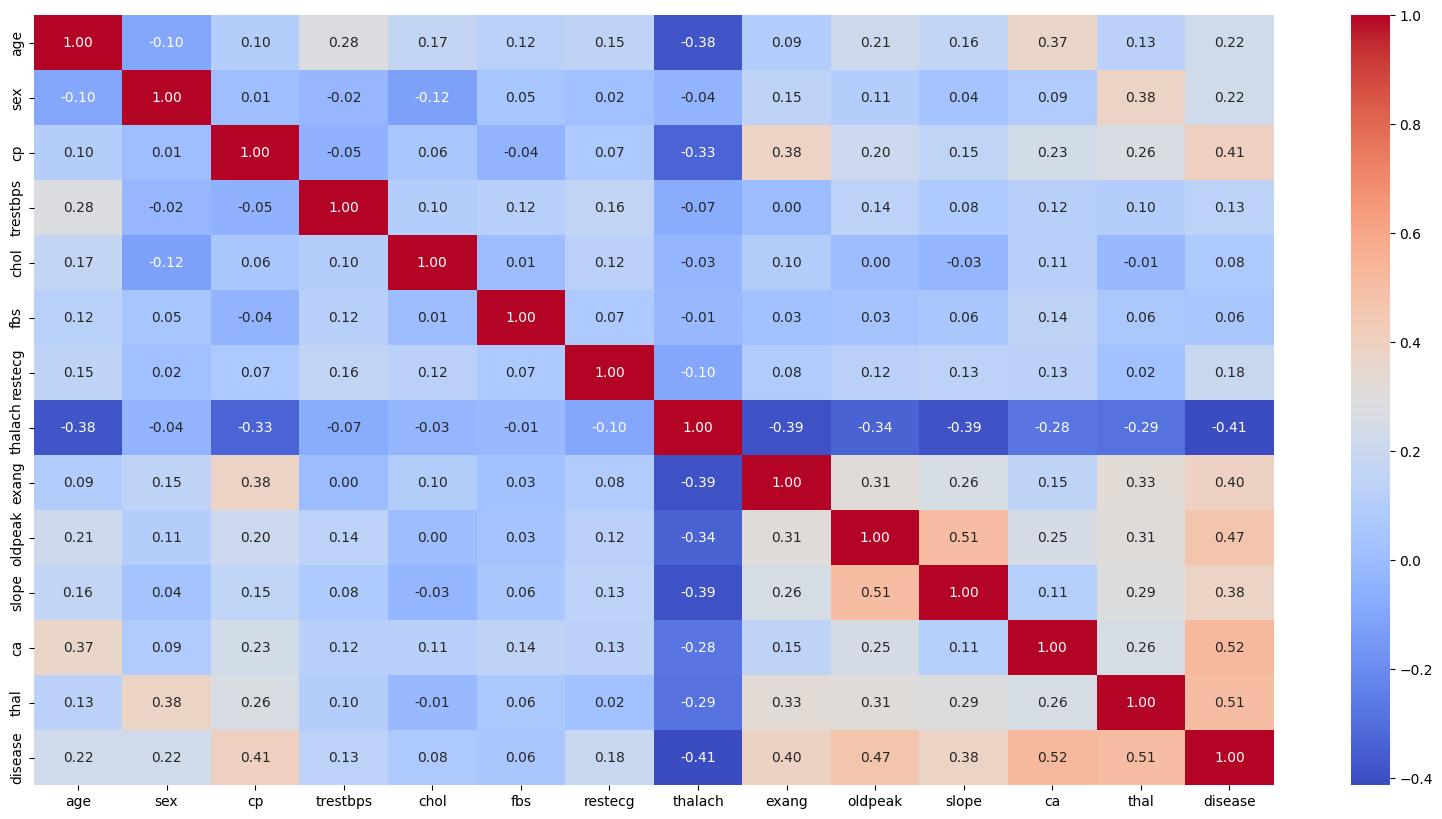

In [ ]:
plt.figure(figsize=(20,10))
sns.heatmap(data_2.corr(), annot=True,cmap='coolwarm',fmt='.2f')

#### Data Relations

Because we have 14 columns , this means if we want show relation between at least 2 of these we will have 13 for each ,so we only show relations between the ones that have correlations above or near 0.30 or -.30 .


**age** 

age has worth looking to corr with below variables : 
* thalach 
* ca 
* disease

In [10]:
Valid_corrlist = ['ca','thalach']
fig , ax = plt.subplots(nrows= 3 , ncols=3 , figsize = (16,10))
sns.scatterplot(x='age',y='thalach',data=data_1,ax=ax[0,0])
sns.scatterplot(x='age',y='thalach',hue='disease',data=data_1,ax=ax[0,1])
a = list(data_1['disease'].unique())
a.remove('N')
data_changed = data_1['disease'].apply(lambda x: 'ill' if x in a else 'not ill')
sns.scatterplot(x='age',y='thalach',hue=data_changed,data=data_1,ax=ax[0,2])
sns.boxplot(x='ca',y='age',data=data_1,ax=ax[1,0])
sns.boxplot(x='ca',y='age',hue='disease',data=data_1,ax=ax[1,1])
sns.boxplot(x='ca',y='age',hue=data_changed,data=data_1,ax=ax[1,2])
sns.boxplot(x='disease',y='age',data=data_1,ax=ax[2,0])
sns.boxplot(x= data_changed,y='age',data=data_1,ax=ax[2,1])

plt.tight_layout()


NameError: name 'plt' is not defined

Age above 54 is ill and below not ill so , we have binary base on target disease .


**Sex**
relations worth looking 
* thal
* disease 
* age 

In [11]:
Valid_corrlist = ['thal','age']
fig , ax = plt.subplots(nrows= 3 , ncols=3 , figsize = (25,14))
sns.boxplot(x='sex',y='age',data=data_1,ax=ax[0,0])
sns.boxplot(x='sex',y='age',hue='disease',data=data_1,ax=ax[0,1])
sns.boxplot(x='sex',y='age',hue=data_changed,data=data_1,ax=ax[0,2])
axe = sns.heatmap(pd.crosstab(data_1['sex'] , data_1['thal']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,0])
axe = sns.heatmap(pd.crosstab([data_1['sex'] , data_1['thal']],data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,1])
axe = sns.heatmap(pd.crosstab([data_1['sex'] , data_1['thal']],data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,2])
axe = sns.heatmap(pd.crosstab(data_1['sex'],data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[2,0])
axe = sns.heatmap(pd.crosstab(data_1['sex'],data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[2,1])

NameError: name 'plt' is not defined

Majority of women are older .
men are more likely to have illness base on plot sex ,age , hue = disease .




**CP**
relations worth looking 
* disease   
* exang 
* thalach 

In [12]:
Valid_corrlist = ['exang','thalach']
fig , ax = plt.subplots(nrows= 3 , ncols=3 , figsize = (20,14))
sns.boxplot(x='cp',y='thalach',data=data_1,ax=ax[0,0])
sns.boxplot(x='cp',y='thalach',hue='disease',data=data_1,ax=ax[0,1])
sns.boxplot(x='cp',y='thalach',hue=data_changed,data=data_1,ax=ax[0,2])
sns.heatmap(pd.crosstab(data_1['sex'] , data_1['exang']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,0])
sns.heatmap(pd.crosstab([data_1['sex'] , data_1['exang']],data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,1])
sns.heatmap(pd.crosstab([data_1['sex'] , data_1['exang']],data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,2])
sns.heatmap(pd.crosstab(data_1['cp'],data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[2,0])
sns.heatmap(pd.crosstab(data_1['cp'],data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[2,1])
plt.show()

NameError: name 'plt' is not defined

most ill people spicially class B,C,D are having the asymtomatic chest pain .
most ill people have lower max heart rate . 
most not ill women have exang no .
highest chest pain for ill poeple is asymtomatic pain .

as we can see most people that are ill have asymtomatic pain , so we put that 1 and other 3 as 0 .


**trestbps**
relations worth looking 
* disease   
* age 


In [13]:
Valid_corrlist = ['age']
fig , ax = plt.subplots(nrows= 1 , ncols=4 , figsize = (20,12))
sns.scatterplot(x='trestbps',y='age',data=data_1,ax=ax[0])
sns.scatterplot(x='trestbps',y='age',hue='disease',data=data_1,ax=ax[1])
sns.scatterplot(x='trestbps',y='age',hue=data_changed,data=data_1,ax=ax[2])
sns.boxplot(x=data_changed,y='trestbps',data=data_1,ax=ax[3])

NameError: name 'plt' is not defined

class D disease has higher blood presure rate .

becuase trest has same distribution for ill and not ill we decided to , 120 to 130 = 0 and 130 to 140 = 1
 


**chol**
worth relations 
* disease

In [14]:
fig , ax = plt.subplots(nrows= 1 , ncols=2 , figsize = (20,12))
sns.boxplot(x='disease',y='chol',data=data_1,ax=ax[0])
sns.boxplot(x=data_changed,y='chol',data=data_1,ax=ax[1])
plt.show()

NameError: name 'plt' is not defined

same thing happens here , 220 to 250 to 0 and 250 280 to 1 .

**fbs**
worth relations 
* disease
* age

In [15]:
Valid_corrlist = ['age']
fig , ax = plt.subplots(nrows= 2 , ncols=3 , figsize = (20,12))
sns.boxplot(x='fbs',y='age',data=data_1,ax=ax[0,0])
sns.boxplot(x='fbs',y='age',hue='disease',data=data_1,ax=ax[0,1])
sns.boxplot(x='fbs',y='age',hue=data_changed,data=data_1,ax=ax[0,2])
axe = sns.heatmap(pd.crosstab(data_1['fbs'] , data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,0])
axe = sns.heatmap(pd.crosstab(data_1['fbs'] , data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,1])

plt.show()

NameError: name 'plt' is not defined

illness and disease has opposite connection . most ill people dont have diabetes.
most people that are ill and have diabetes are old .
 

 

**restecg**
worth looking 
* age

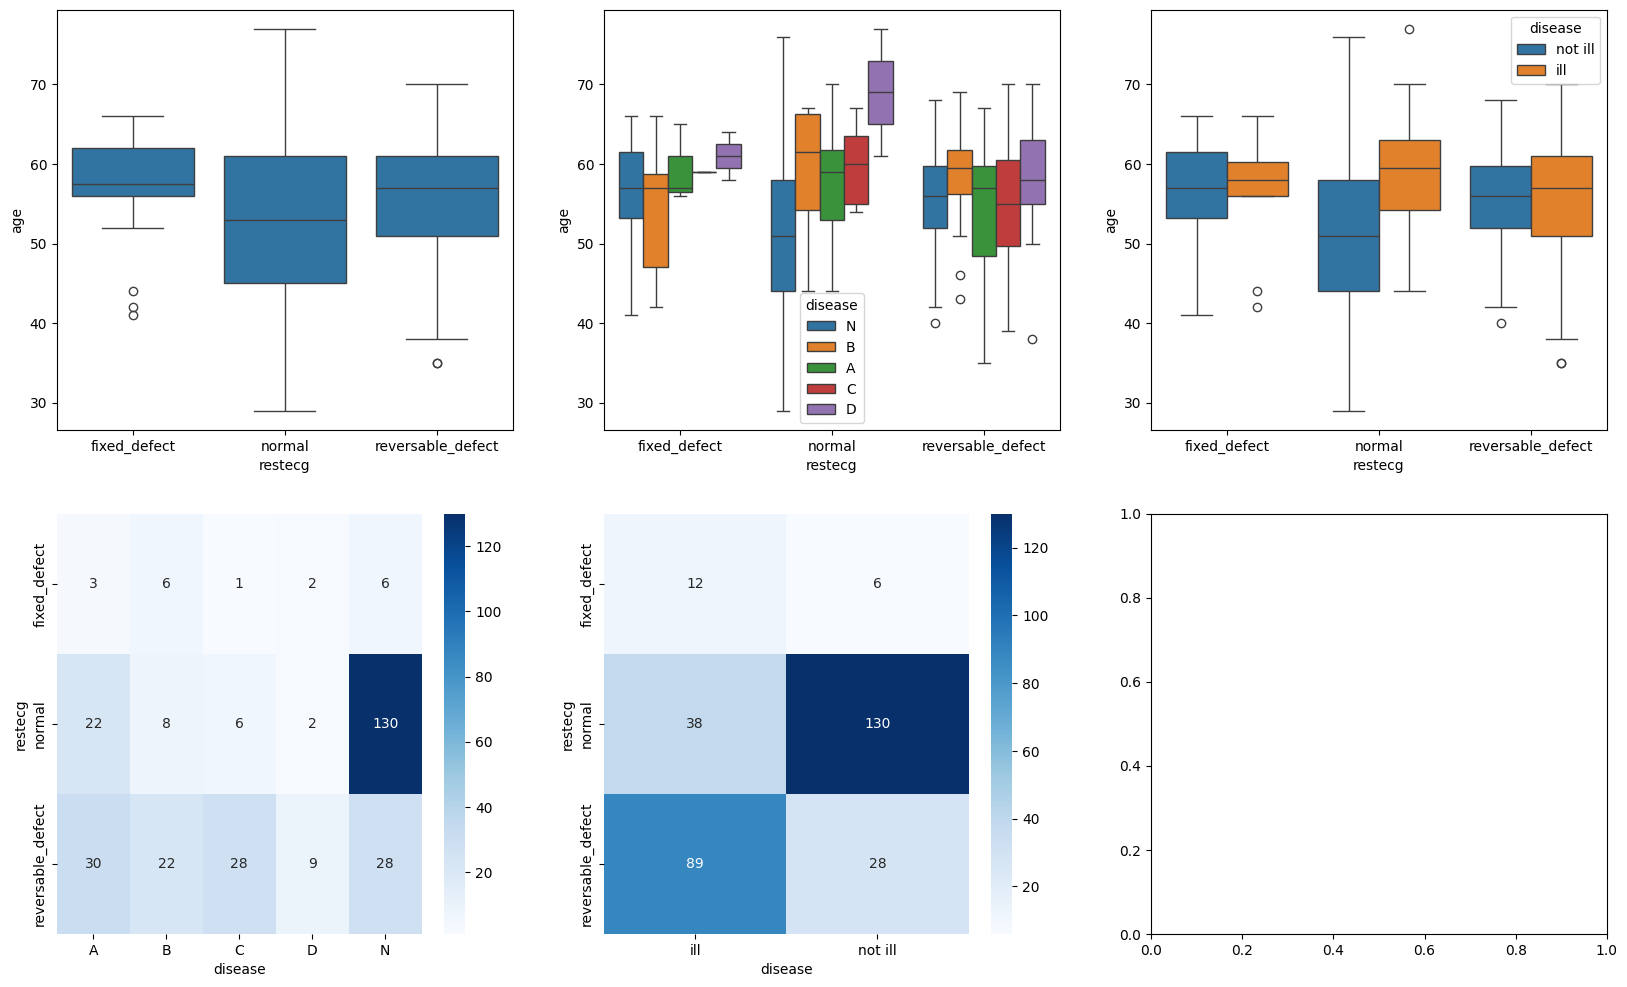

In [ ]:
Valid_corrlist = ['age']
fig , ax = plt.subplots(nrows= 2 , ncols=3 , figsize = (20,12))
sns.boxplot(x='restecg',y='age',data=data_1,ax=ax[0,0])
sns.boxplot(x='restecg',y='age',hue='disease',data=data_1,ax=ax[0,1])
sns.boxplot(x='restecg',y='age',hue=data_changed,data=data_1,ax=ax[0,2])
axe = sns.heatmap(pd.crosstab(data_1['restecg'] , data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,0])
axe = sns.heatmap(pd.crosstab(data_1['restecg'] , data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,1])

plt.show()

class A,C,D are older and have normal and reversable defect . 
most class B that are older have fixed defect .


most ill poeople have reversed_defact , so it is 1 and other 2 is  0 


**thalach**
relations worth looking 
* disease
* slope 
* exang 

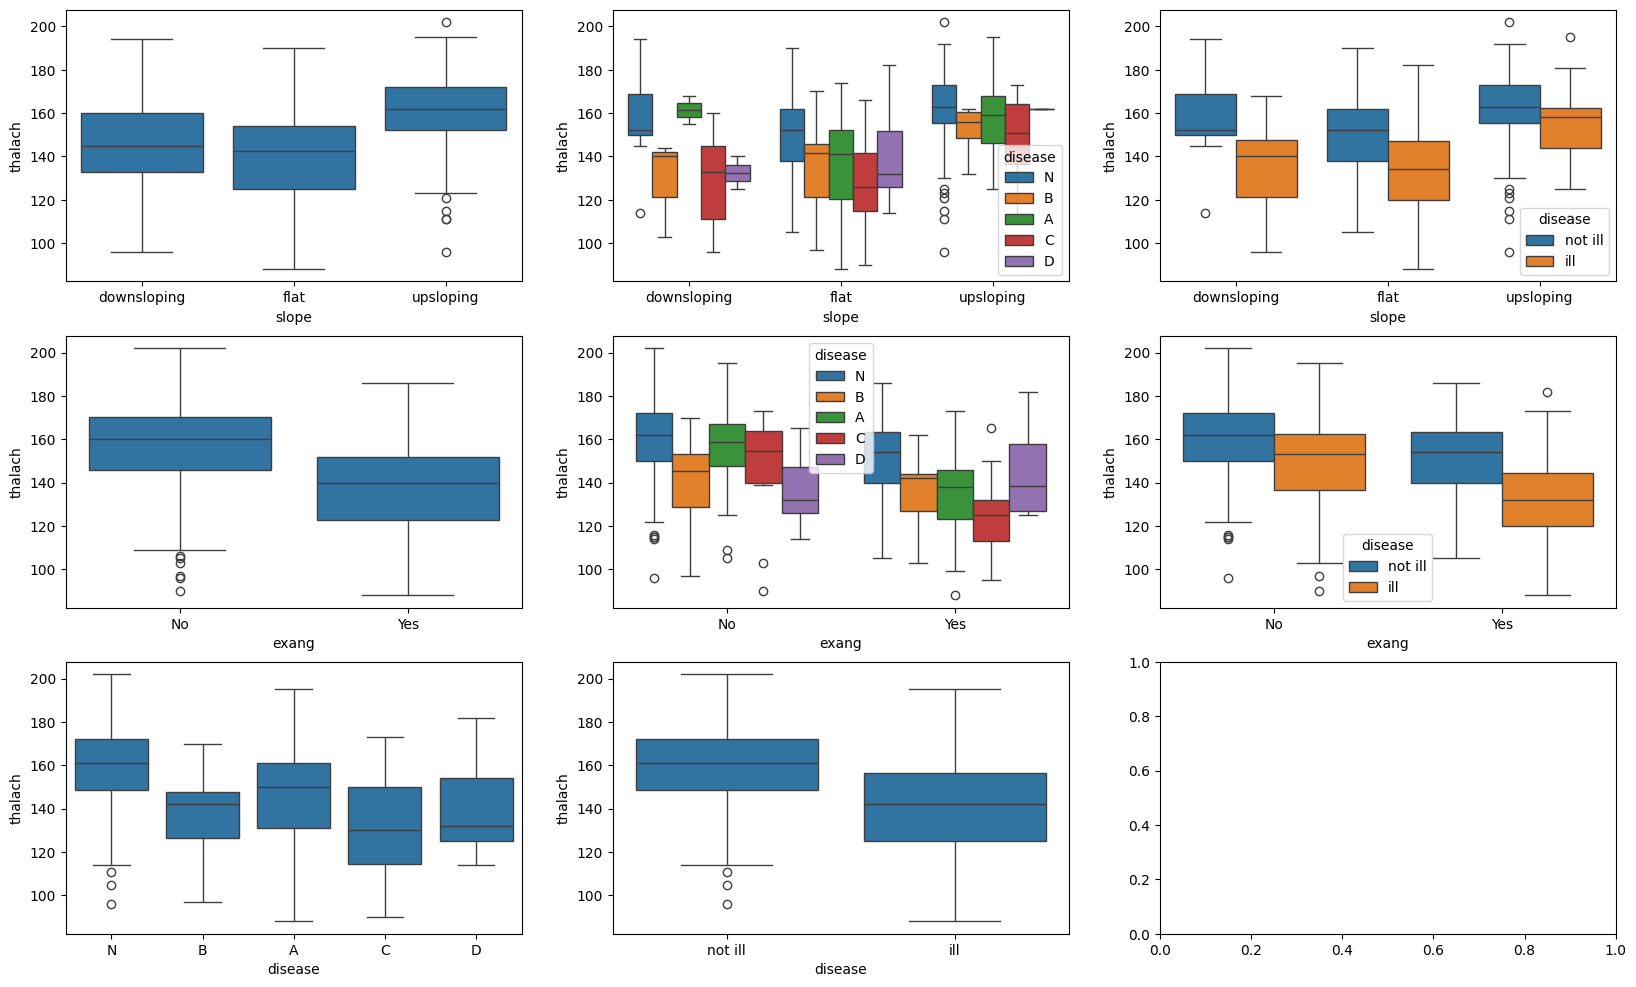

In [ ]:
Valid_corrlist = ['exang','thalach']
fig , ax = plt.subplots(nrows=3 , ncols=3 , figsize = (20,12))
sns.boxplot(x='slope',y='thalach',data=data_1,ax=ax[0,0])
sns.boxplot(x='slope',y='thalach',hue='disease',data=data_1,ax=ax[0,1])
sns.boxplot(x='slope',y='thalach',hue=data_changed,data=data_1,ax=ax[0,2])
sns.boxplot(x='exang',y='thalach',data=data_1,ax=ax[1,0])
sns.boxplot(x='exang',y='thalach',hue='disease',data=data_1,ax=ax[1,1])
sns.boxplot(x='exang',y='thalach',hue=data_changed,data=data_1,ax=ax[1,2])
sns.boxplot(x='disease',y='thalach',data=data_1,ax=ax[2,0])
sns.boxplot(x= data_changed,y='thalach',data=data_1,ax=ax[2,1])
plt.show()


upsloping has higher max heart rate . most ill people class D have flat slope .
other classes  are mostly have flat slope and upsloping .
most ill people with exang yes has lower max heart rate .
 130 to 150 to 1 and 150 to 180 to 0 .




**exang**
worth looking 
* disease
* thal

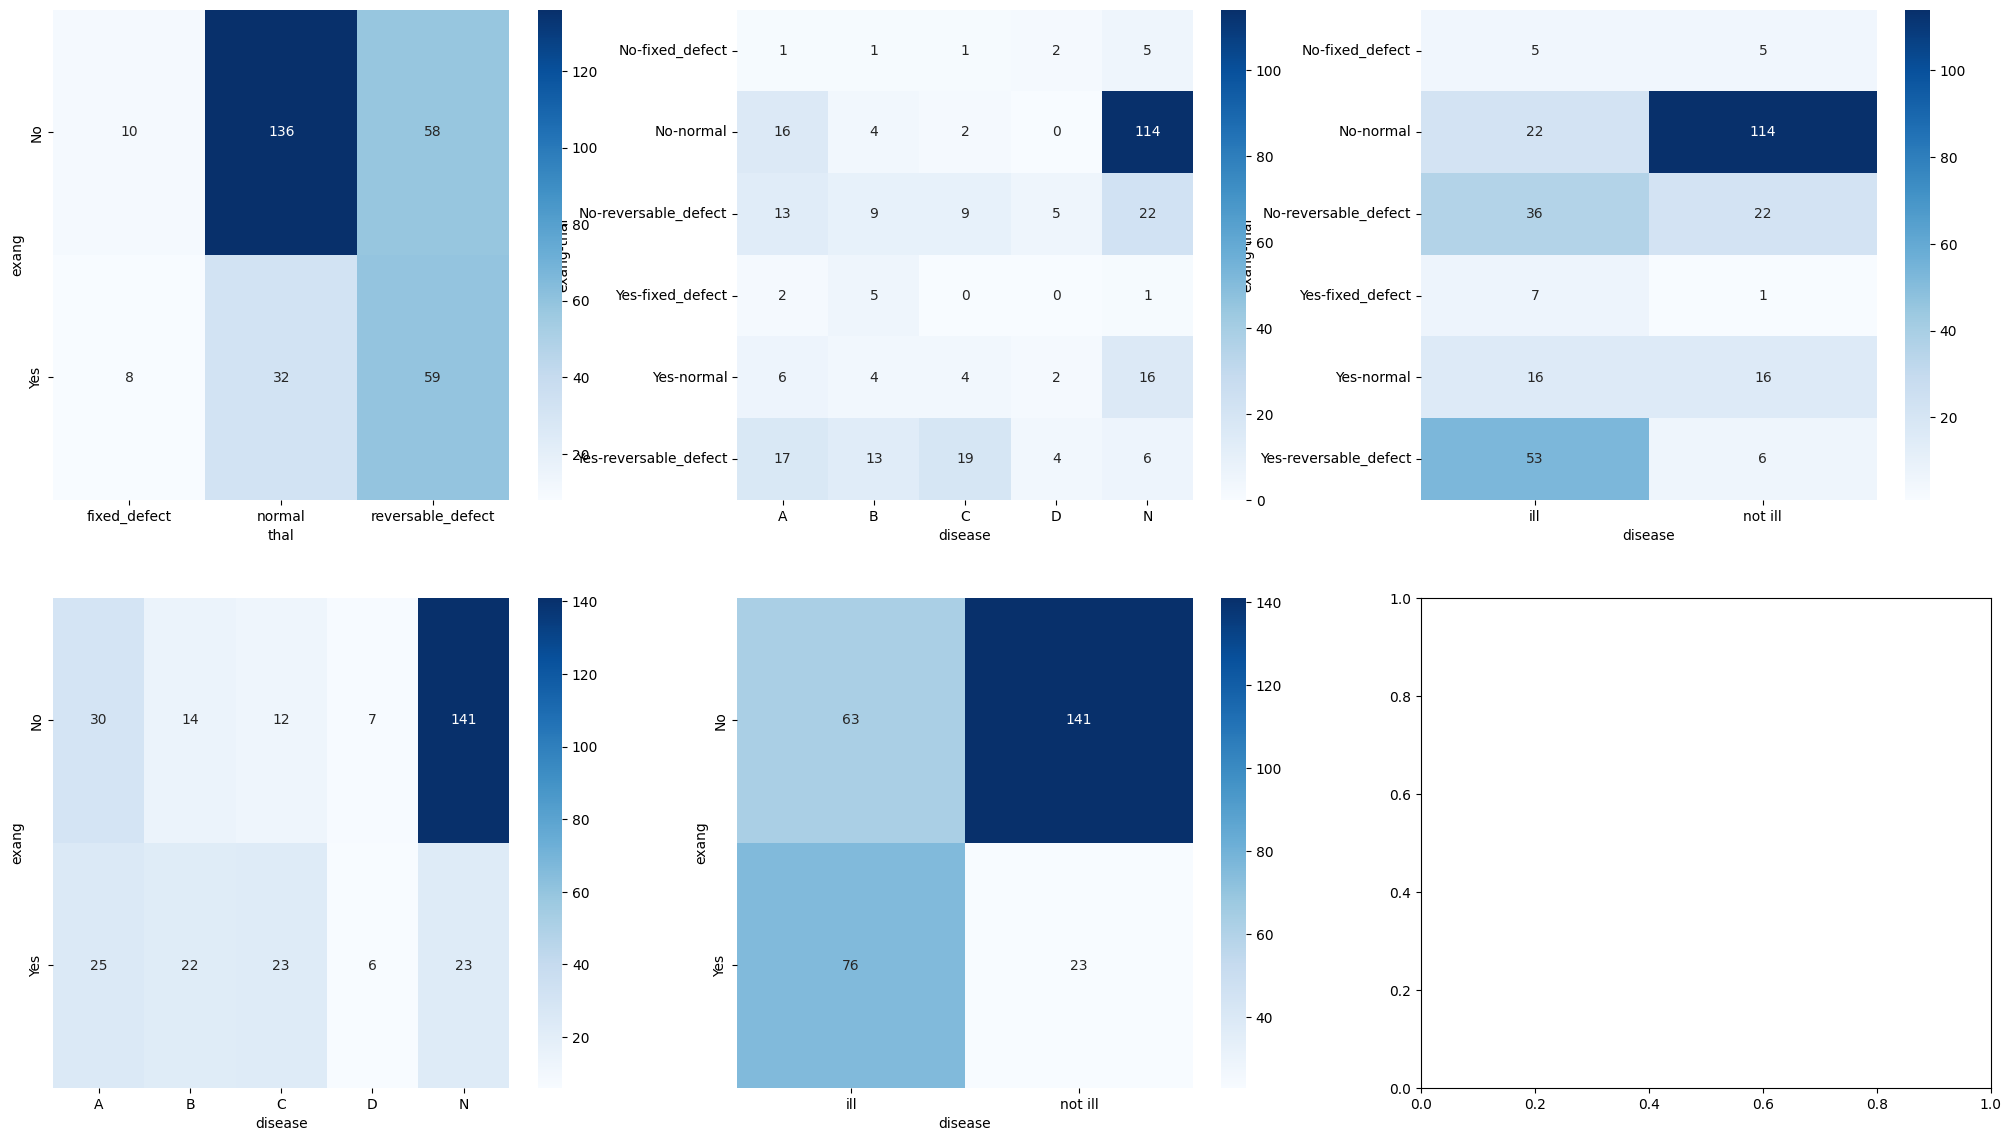

In [ ]:
Valid_corrlist = ['thal']
fig , ax = plt.subplots(nrows= 2 , ncols=3 , figsize = (25,14))
sns.heatmap(pd.crosstab(data_1['exang'] , data_1['thal']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[0,0])
sns.heatmap(pd.crosstab([data_1['exang'] , data_1['thal']],data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[0,1])
sns.heatmap(pd.crosstab([data_1['exang'] , data_1['thal']],data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[0,2])
sns.heatmap(pd.crosstab(data_1['exang'] , data_1['disease']) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,0])
sns.heatmap(pd.crosstab(data_1['exang'] ,data_changed) , annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,1])
plt.show()

most not ill people have normal thal .
most ill people have yes reversable defect .



**oldpeak**
worth looking 
* disease
* slope

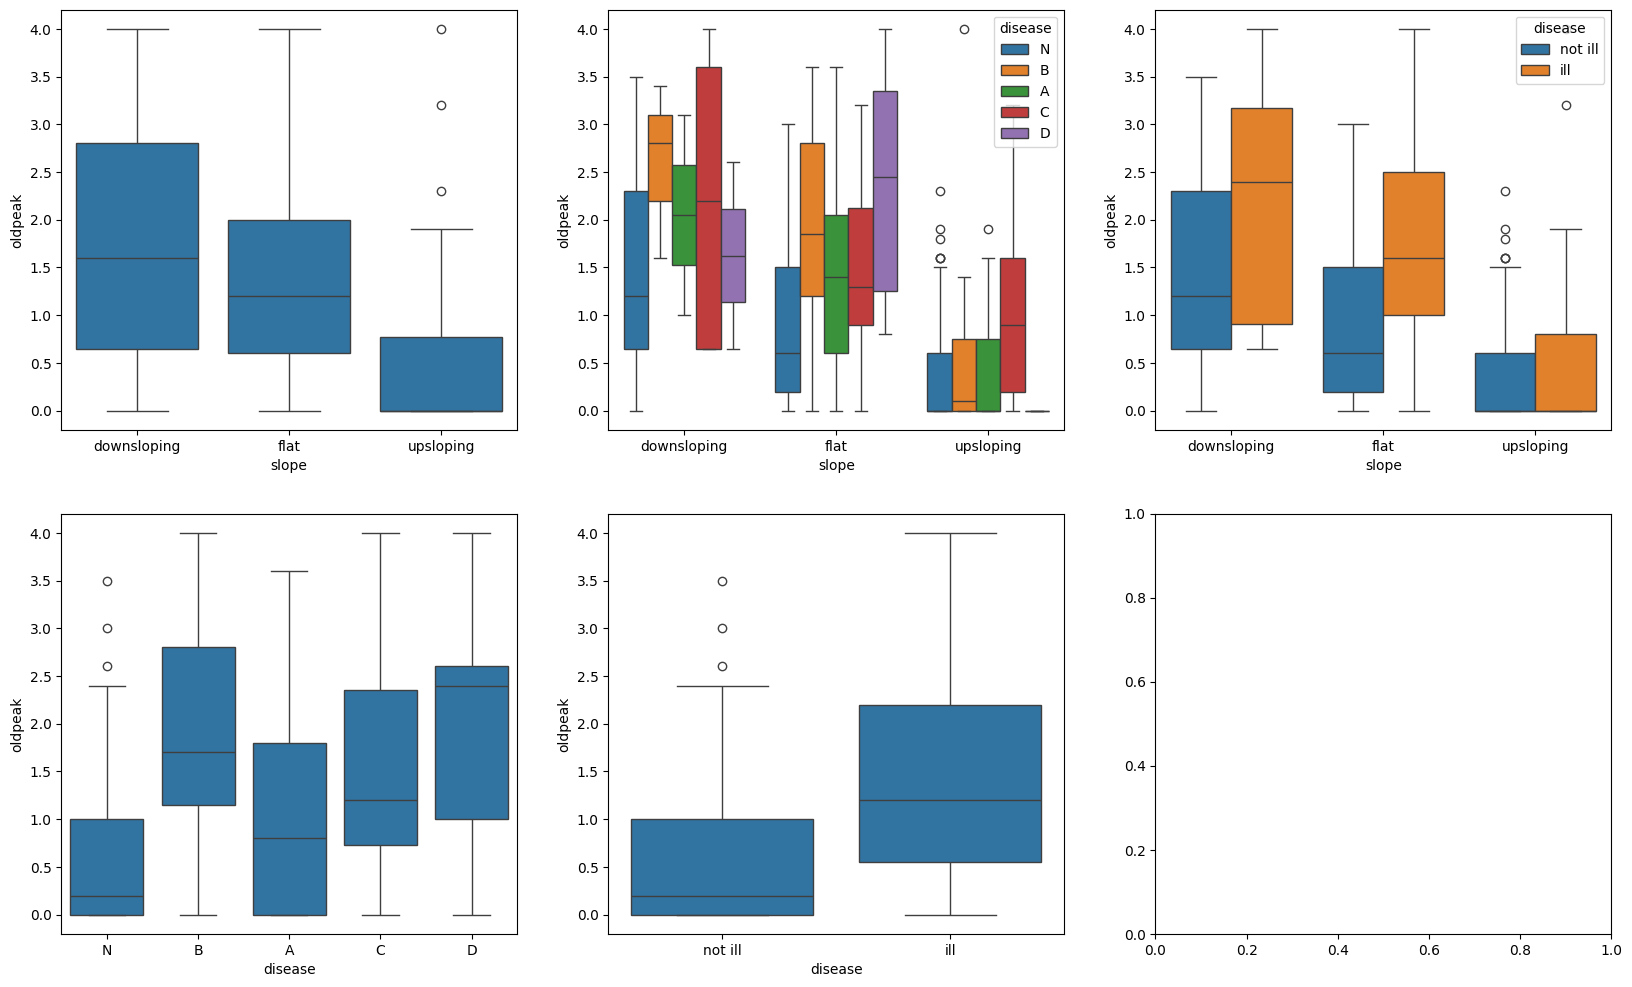

In [ ]:
Valid_corrlist = ['slope']
fig , ax = plt.subplots(nrows= 2 , ncols=3 , figsize = (20,12))
sns.boxplot(x= 'slope',y='oldpeak',data=data_1,ax=ax[0,0])
sns.boxplot(x= 'slope',y='oldpeak',hue='disease' ,data=data_1,ax=ax[0,1])
sns.boxplot(x= 'slope',y='oldpeak',hue=data_changed,data=data_1,ax=ax[0,2])
sns.boxplot(x= 'disease',y='oldpeak',data=data_1,ax=ax[1,0])
sns.boxplot(x= data_changed,y='oldpeak',data=data_1,ax=ax[1,1])
plt.show()

downsloping and flat slope has oldpeak rate over 1 and upsloping has rate lower then 1 .
most ill people has oldpeak rate higher then 1 , and not ill have less then 1 .

above .7 is 1 and below .7 is 0 
 

**slope**
worth looking
* disease


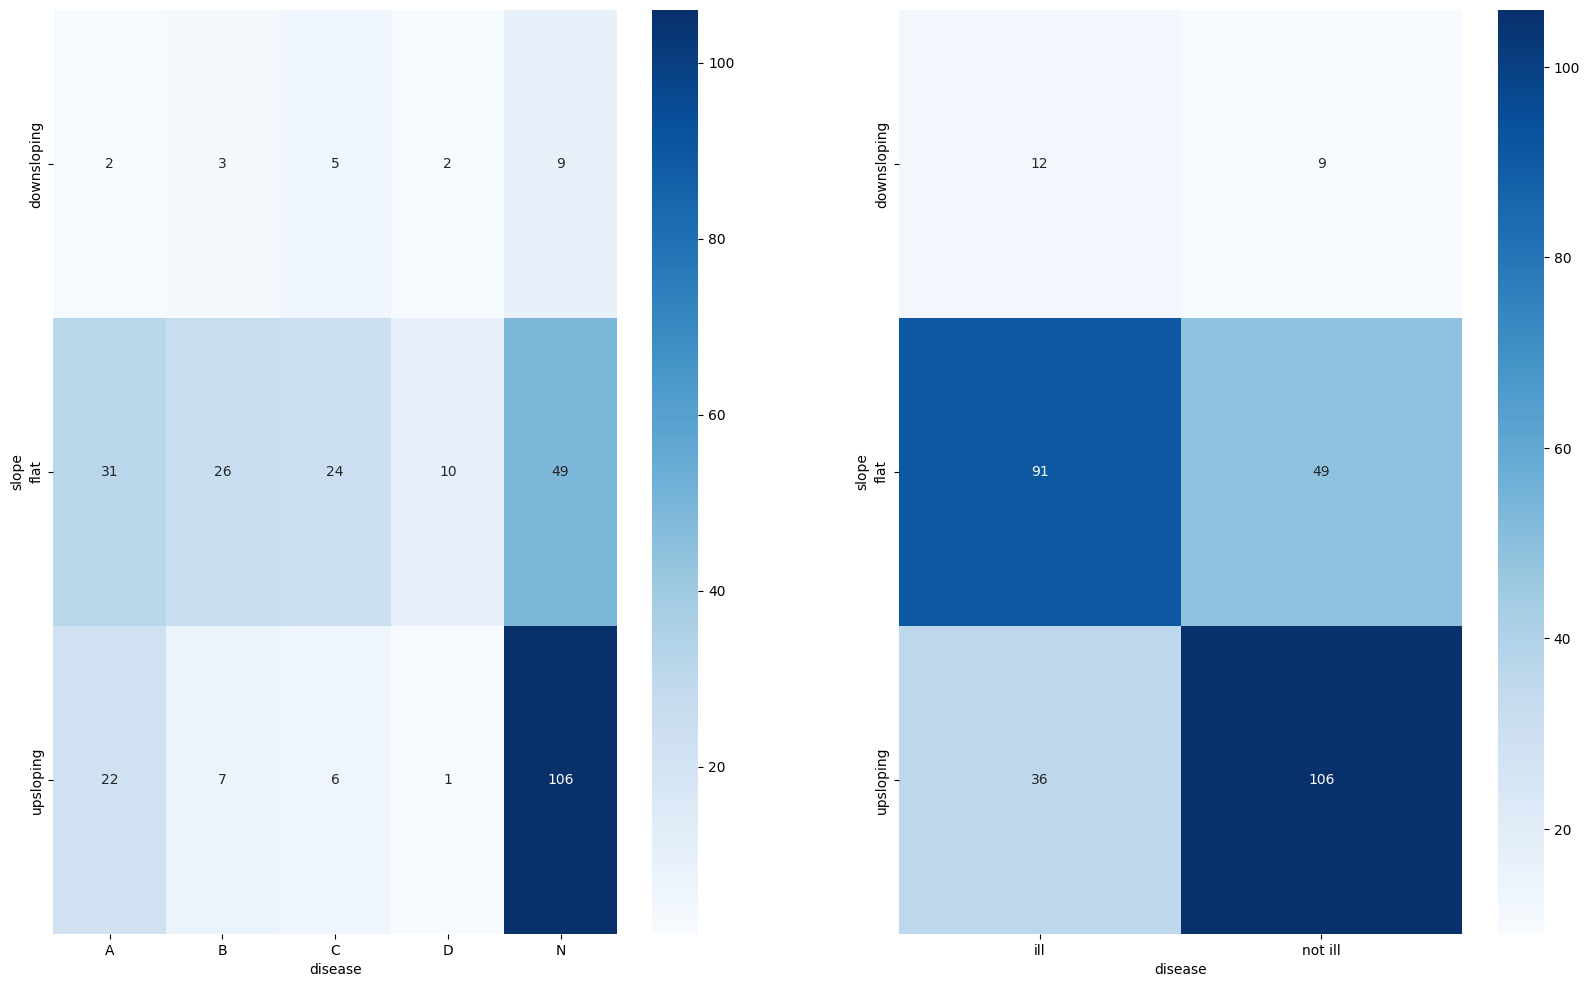

In [ ]:
Valid_corrlist = ['disease']
fig , ax = plt.subplots(nrows= 1 , ncols=2 , figsize = (20,12))
sns.heatmap(pd.crosstab(data_1['slope'],data_1['disease']),annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[0])
sns.heatmap(pd.crosstab(data_1['slope'],data_changed),annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1])
plt.show()

most healthy people have upsloping  and flat slope .


flat slope is 1 and other 2 is 0 .


**ca**
worth looking 
* disease

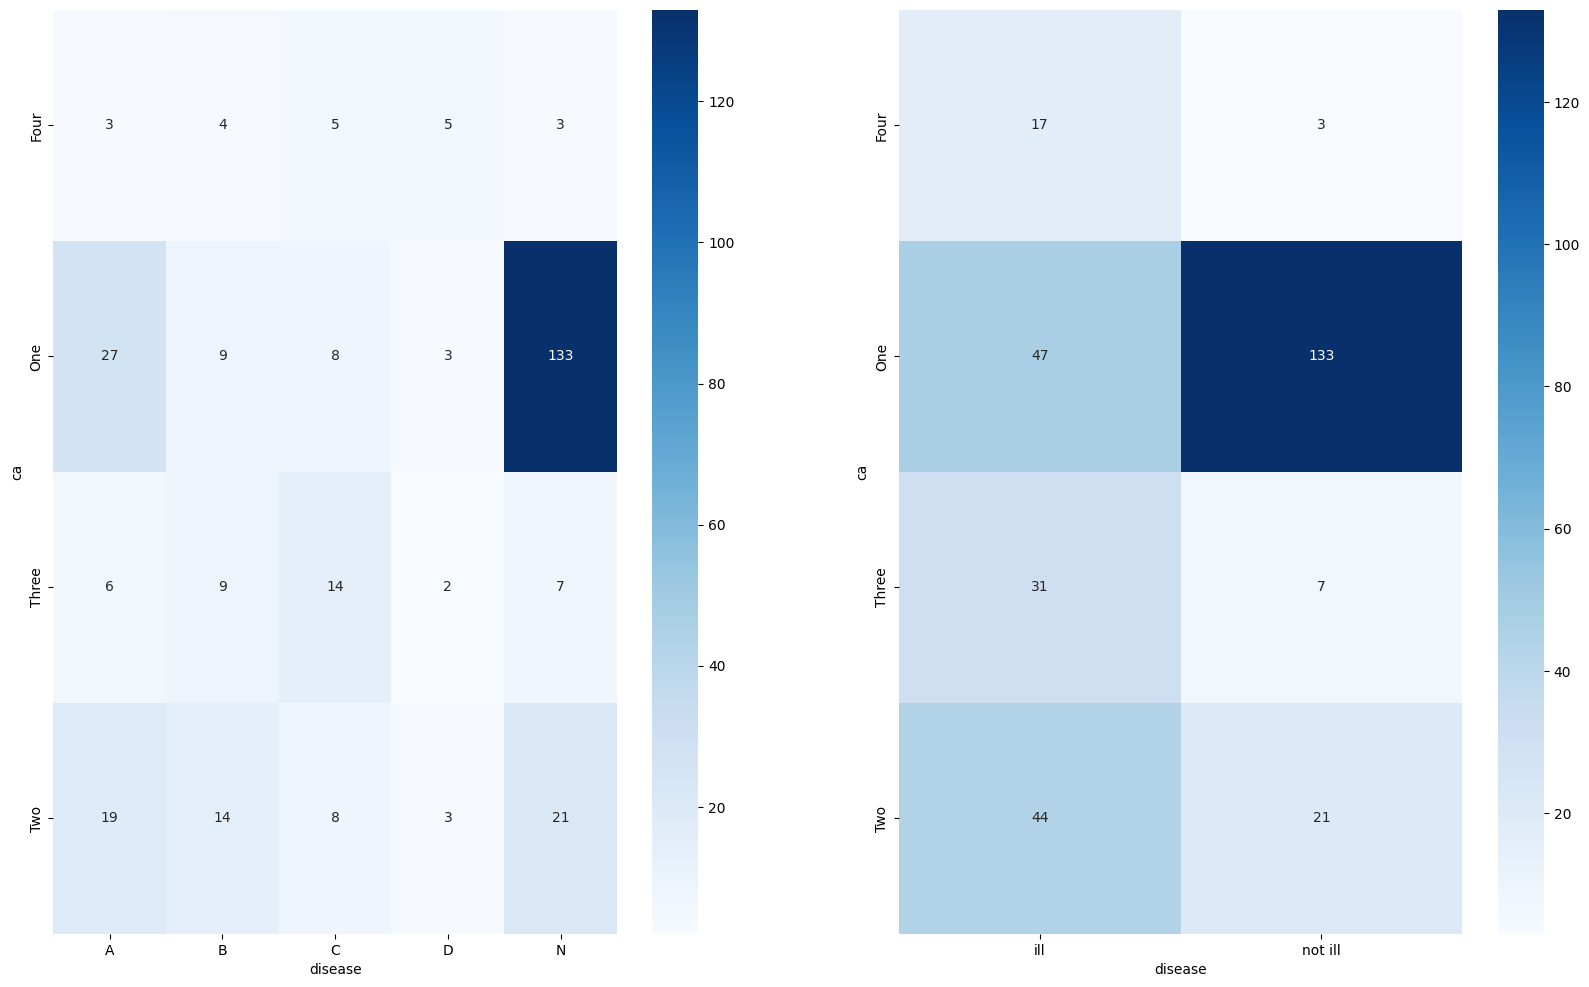

In [ ]:
Valid_corrlist = ['disease']
fig , ax = plt.subplots(nrows= 1 , ncols=2 , figsize = (20,12))
sns.heatmap(pd.crosstab(data_1['ca'],data_1['disease']),annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[0])
sns.heatmap(pd.crosstab(data_1['ca'],data_changed),annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1])
plt.show()

most ill people have more then 1  vessels blocked . 
most healthy people have less then 1 vessels blocked

because most not ill is in one , so one is 0 and other 3 is 1 .

**thal**
worth looking 

* disease
* oldpeak

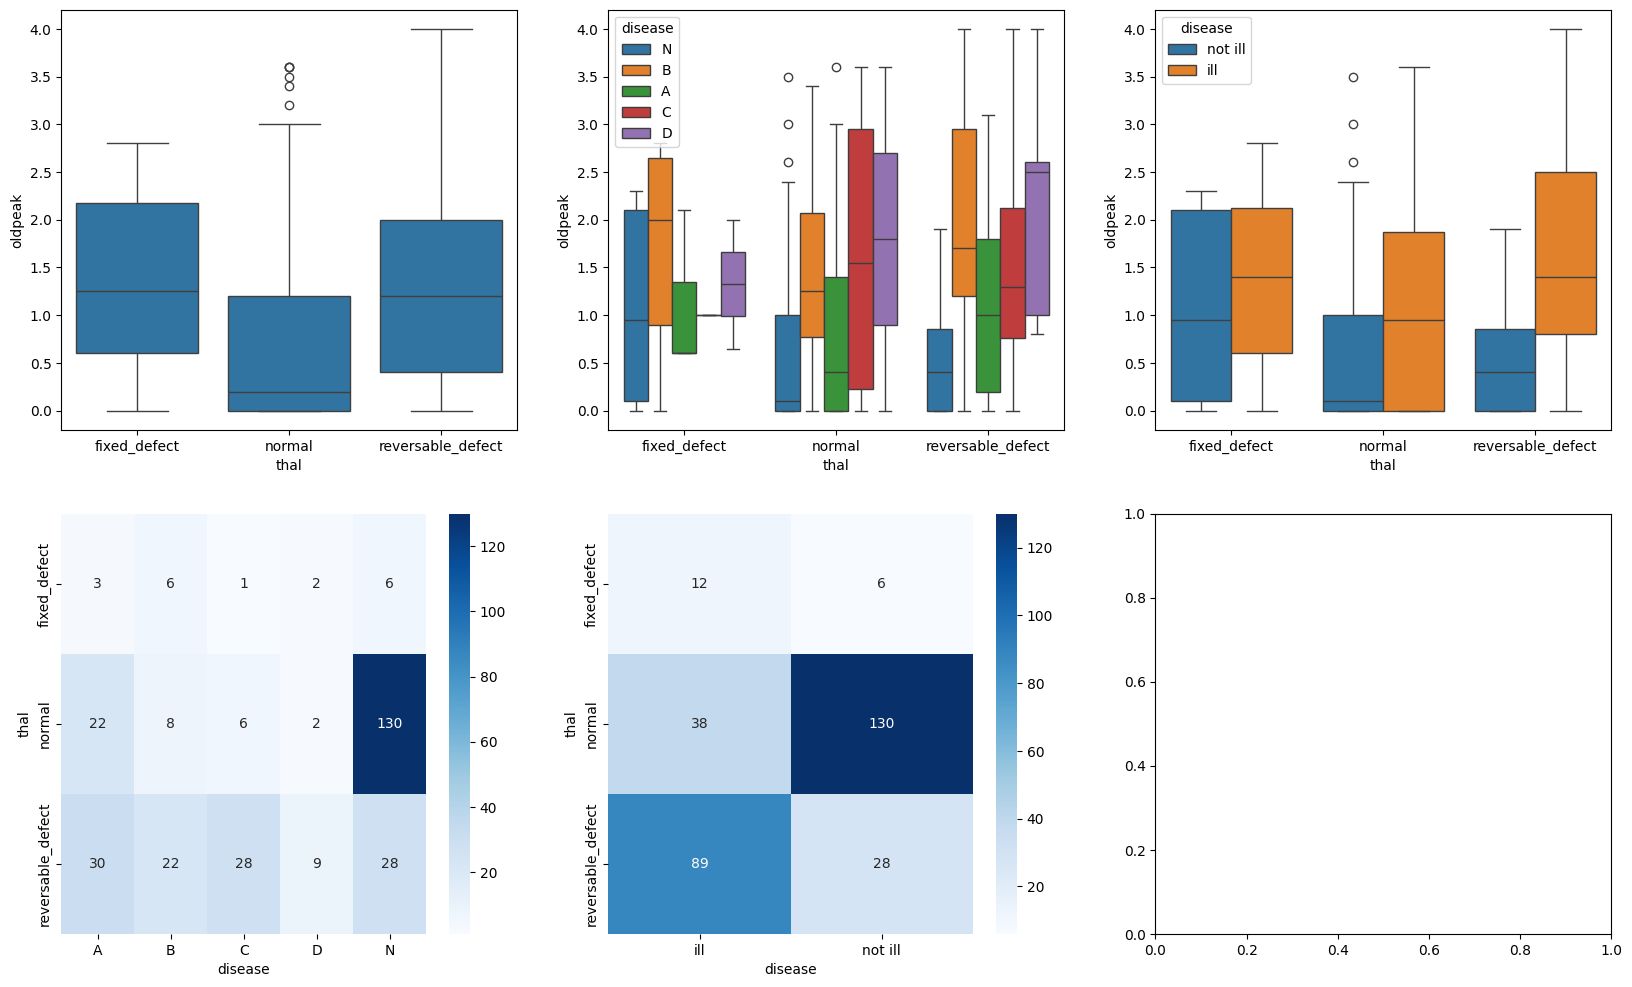

In [ ]:
Valid_corrlist = ['oldpeak']
fig , ax = plt.subplots(nrows= 2 , ncols=3 , figsize = (20,12))
sns.boxplot(x= 'thal',y='oldpeak',data=data_1,ax=ax[0,0])
sns.boxplot(x= 'thal',y='oldpeak',hue='disease' ,data=data_1,ax=ax[0,1])
sns.boxplot(x= 'thal',y='oldpeak',hue=data_changed,data=data_1,ax=ax[0,2])
sns.heatmap(pd.crosstab(data_1['thal'],data_1['disease']),annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,0])
sns.heatmap(pd.crosstab(data_1['thal'],data_changed),annot=True, fmt="d", cmap="Blues", cbar=True,ax=ax[1,1])
plt.show()

in reversable defect  ill people have oldpeak more then 1 , and in others is between 0 to 2 .

normal is 0 cuz most not ill and other 2 is 1 .

**Applying the changes**
now we start to apply changes base on the analises .

In [ ]:
data_1_temp = data_1.copy(deep=True)
for i in data_1.select_dtypes('object'):
    print(f"column {i}",data_1[i].unique())
print(data_1.keys())
data_temp = data_1.copy(deep=True)

column sex ['Male' 'Female']
column cp ['typical_angina' 'asymtomatic' 'non-anginal pain' 'atypical_angina']
column fbs ['True' 'False']
column restecg ['fixed_defect' 'normal' 'reversable_defect']
column exang ['No' 'Yes']
column slope ['downsloping' 'flat' 'upsloping']
column ca ['One' 'Four' 'Three' 'Two']
column thal ['fixed_defect' 'normal' 'reversable_defect']
column disease ['N' 'B' 'A' 'C' 'D']
Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'disease'],
      dtype='object')


In [ ]:
data_1['age'] = data_1['age'].apply(lambda x : 0 if x < 54 else 1)
data_1['trestbps'] = data_1['trestbps'].apply(lambda x : 0 if x < 130 else 1)
data_1['chol'] = data_1['chol'].apply(lambda x : 0 if x < 250 else 1)
data_1['thalach'] = data_1['thalach'].apply(lambda x : 0 if x < 150 else 1)
data_1['oldpeak'] = data_1['oldpeak'].apply(lambda x : 0 if x < .7 else 1)
data_1['cp'] = data_1['cp'].apply(lambda x : 1 if x == 'asymtomatic' else 0)
data_1['restecg'] = data_1['restecg'].apply(lambda x : 1 if x == 'reversable_defect' else 0)
data_1['slope'] = data_1['slope'].apply(lambda x : 1 if x == 'flat' else 0)
data_1['ca'] = data_1['ca'].apply(lambda x : 1 if x == 'One' else 0)
data_1['thal'] = data_1['thal'].apply(lambda x : 1 if x == 'normal' else 0)
data_1['disease'] = data_1['disease'].apply(lambda x : 0 if x == 'N' else 1)
data_1['sex'] = data_1['sex'].apply(lambda x : 0 if x == 'male' else 1)
data_1['fbs'] = data_1['fbs'].apply(lambda x : 0 if x == 'No' else 1)
data_1['exang'] = data_1['exang'].apply(lambda x : 0 if x == 'False' else 1)
for i in data_1.keys():
    print('column :',data_1[i].value_counts())


column : age
1    176
0    127
Name: count, dtype: int64
column : sex
1    303
Name: count, dtype: int64
column : cp
0    159
1    144
Name: count, dtype: int64
column : trestbps
1    168
0    135
Name: count, dtype: int64
column : chol
0    178
1    125
Name: count, dtype: int64
column : fbs
1    303
Name: count, dtype: int64
column : restecg
0    186
1    117
Name: count, dtype: int64
column : thalach
1    172
0    131
Name: count, dtype: int64
column : exang
1    303
Name: count, dtype: int64
column : oldpeak
0    154
1    149
Name: count, dtype: int64
column : slope
0    163
1    140
Name: count, dtype: int64
column : ca
1    180
0    123
Name: count, dtype: int64
column : thal
1    168
0    135
Name: count, dtype: int64
column : disease
0    164
1    139
Name: count, dtype: int64


**Association rules**
now we apply the method in order to get best confidence in our data . 

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
# Generate association rules
min_support = 0.1  # Example, adjust as needed
frequent_itemsets = apriori(data_1, min_support=min_support, use_colnames=True)
print(frequent_itemsets)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.8)

# Display association rules
print("Association Rules:")
print(rules)



# Extract the list of transactions and their confidence
transactions_with_confidence = rules[['antecedents', 'consequents', 'confidence']]

# Display the transactions with confidence
print("\nTransactions with Confidence:")
print(transactions_with_confidence)


       support                                           itemsets
0     0.580858                                              (age)
1     1.000000                                              (sex)
2     0.475248                                               (cp)
3     0.554455                                         (trestbps)
4     0.412541                                             (chol)
...        ...                                                ...
1890  0.102310  (sex, chol, oldpeak, slope, fbs, exang, diseas...
1891  0.125413  (sex, oldpeak, slope, fbs, exang, restecg, dis...
1892  0.112211  (sex, oldpeak, fbs, exang, trestbps, restecg, ...
1893  0.112211  (sex, oldpeak, slope, fbs, exang, trestbps, cp...
1894  0.132013  (sex, oldpeak, slope, fbs, exang, restecg, cp,...

[1895 rows x 2 columns]
Association Rules:
                        antecedents                          consequents  \
0                             (age)                                (sex)   
1           

C:\Users\drmey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\mlxtend\frequent_patterns\fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


as we can see the result because we have low min sup , there are to many transaction list to check ,so we increase the amount of minsup to get more strong relations and more frequent ones.
trying for `.1 to .3`.

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
# Generate association rules
min_support = 0.3  # Example, adjust as needed 
frequent_itemsets = apriori(data_1, min_support=min_support, use_colnames=True)
print(frequent_itemsets)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.8)

# Display association rules
print("Association Rules:")
print(rules)

# Extract the list of transactions and their confidence
transactions_with_confidence = rules[['antecedents', 'consequents', 'confidence']]

# Display the transactions with confidence
print("\nTransactions with Confidence:")
print(transactions_with_confidence)

C:\Users\drmey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\mlxtend\frequent_patterns\fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


      support                              itemsets
0    0.580858                                 (age)
1    1.000000                                 (sex)
2    0.475248                                  (cp)
3    0.554455                            (trestbps)
4    0.412541                                (chol)
..        ...                                   ...
218  0.300330     (sex, slope, fbs, exang, disease)
219  0.392739           (sex, thal, fbs, ca, exang)
220  0.303630       (sex, thal, ca, exang, thalach)
221  0.303630       (thal, fbs, ca, exang, thalach)
222  0.303630  (sex, thal, fbs, ca, exang, thalach)

[223 rows x 2 columns]
Association Rules:
                         antecedents        consequents  antecedent support  \
0                              (age)              (sex)            0.580858   
1                              (age)              (fbs)            0.580858   
2                              (age)            (exang)            0.580858   
3                

we try for more min sup , `.3 to .6`.

In [ ]:
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
# Generate association rules
min_support = 0.6  # Example, adjust as needed 
frequent_itemsets = apriori(data_1, min_support=min_support, use_colnames=True)
print(frequent_itemsets)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.8)

# Display association rules
print("Association Rules:")
print(rules)

# Extract the list of transactions and their confidence
transactions_with_confidence = rules[['antecedents', 'consequents', 'confidence']]

# Display the transactions with confidence
print("\nTransactions with Confidence:")
print(transactions_with_confidence)

   support           itemsets
0      1.0              (sex)
1      1.0              (fbs)
2      1.0            (exang)
3      1.0         (sex, fbs)
4      1.0       (sex, exang)
5      1.0       (fbs, exang)
6      1.0  (sex, fbs, exang)
Association Rules:
     antecedents   consequents  antecedent support  consequent support  \
0          (sex)         (fbs)                 1.0                 1.0   
1          (fbs)         (sex)                 1.0                 1.0   
2          (sex)       (exang)                 1.0                 1.0   
3        (exang)         (sex)                 1.0                 1.0   
4          (fbs)       (exang)                 1.0                 1.0   
5        (exang)         (fbs)                 1.0                 1.0   
6     (sex, fbs)       (exang)                 1.0                 1.0   
7   (sex, exang)         (fbs)                 1.0                 1.0   
8   (fbs, exang)         (sex)                 1.0                 1.0   
9

C:\Users\drmey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\mlxtend\frequent_patterns\fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


as we can see if we pick higher min sup , we might loss some important trasnactions , so its always better to check for low values then start with high .

# Clustering 

Clustering Methods in Machine Learning
Clustering is a type of unsupervised learning where the goal is to group similar data points together. The main objective is to discover inherent patterns or structures within the data without predefined labels. In Jupyter Notebook, various clustering methods can be implemented using libraries like scikit-learn.

* **K-Means Clustering:**

Advantages: Simple and computationally efficient. Works well when the number of clusters is known.
Considerations: Assumes spherical clusters and may not perform well with irregularly shaped or varying-sized clusters.


* **Hierarchical Clustering:**

Advantages: Captures hierarchical relationships in the data. No need to specify the number of clusters in advance.
Considerations: Computationally expensive for large datasets. Interpretation of the dendrogram may vary.


* **DBSCAN (Density-Based Spatial Clustering of Applications with Noise):**

Advantages: Robust to outliers and can discover clusters of arbitrary shapes. No need to specify the number of clusters.
Considerations: Sensitive to the choice of hyperparameters, such as epsilon and minimum points.


* **Mean-Shift Clustering:**

Advantages: Automatically determines the number of clusters. Robust to varying cluster shapes and densities.
Considerations: Computationally expensive, especially for large datasets.


* **Agglomerative Clustering:**

Advantages: Hierarchical structure allows for flexible interpretation. No need to specify the number of clusters.
Considerations: Computationally expensive for large datasets. Choice of linkage criteria can impact results.

## **k-means method explain**


K-Means is a popular clustering algorithm that partitions a dataset into K distinct, non-overlapping subsets (clusters). The goal of K-Means is to assign each data point to a cluster in a way that minimizes the sum of squared distances between data points and the centroid of their assigned cluster. The algorithm follows these steps:

Initialization:

Choose the number of clusters, K.
Randomly initialize K cluster centroids. Each centroid represents the mean of the data points assigned to that cluster.
Assignment Step:

For each data point, calculate the Euclidean distance to each centroid.
Assign the data point to the cluster whose centroid is the closest.
Update Step:

Recalculate the centroids of the clusters based on the newly assigned data points.
The new centroid is the mean of all data points assigned to that cluster.
Repeat Steps 2 and 3:

Repeat the Assignment and Update steps until convergence. Convergence occurs when the centroids no longer change significantly or when a specified number of iterations is reached.
Final Result:

The algorithm produces K clusters, and each data point is assigned to one of these clusters.
The algorithm aims to minimize the within-cluster sum of squared distances, also known as the inertia or within-cluster sum of squares. K-Means has some characteristics and considerations:

Sensitivity to Initialization:

The final clusters may depend on the initial random placement of centroids. To mitigate this, the algorithm is often run multiple times with different initializations, and the best result is chosen.
Number of Clusters (K):

The choice of the number of clusters (K) is crucial and often requires domain knowledge or using techniques like the elbow method or silhouette analysis to find an optimal K.
Assumption of Spherical Clusters:

K-Means assumes that clusters are spherical and equally sized. It may not perform well on clusters with varying shapes, sizes, or densities.
Scalability:

K-Means is computationally efficient and scales well with large datasets.
Normalization:

Feature normalization is often recommended to ensure that all features contribute equally to the distance calculation.

**Data Coding Readable**
in order to use any model for learning , we need to code data inorder to machine understands it .
therefore we the following methods to map any data .


**ordinal**
* ordinalencoder


**continous**
* standardscaler

and in order to use model on this data , we need to use pipeline for applying the changes and using machine to learn data .
before we do that , first we change data into ordinal form .

In [ ]:
# adjusting the ordinal columns : 
list_A = []
list_B = []
list_C = []
for i in data_temp.select_dtypes(object):
    if len(data_temp[i].unique().tolist())>2:
        list_A.append(data_temp[i].unique().tolist())
        list_B.append(i)
        list_C.append(data_2[i].unique().tolist())
list_A.pop()
print(list_A) # ordinal values for ordinal columns , in order of read 
print(list_B) # correspond columns  
print(list_C)

[['typical_angina', 'asymtomatic', 'non-anginal pain', 'atypical_angina'], ['fixed_defect', 'normal', 'reversable_defect'], ['downsloping', 'flat', 'upsloping'], ['One', 'Four', 'Three', 'Two'], ['fixed_defect', 'normal', 'reversable_defect']]
['cp', 'restecg', 'slope', 'ca', 'thal', 'disease']
[[1, 4, 3, 2], [2, 0, 1], [3, 2, 1], [0.0, 3.0, 2.0, 1.0], [6.0, 3.0, 7.0], [0, 2, 1, 3, 4]]


In [ ]:
# chaning the ordinal values in each data , these code is for changing each data we have with the ordinal names of data ,
#  using coding and not direct
result_list = []
for i,j,k in zip(list_B,list_A,list_C):
    key = f'{i}'
    new_dict = {}
    for m , n in zip(k,j):
            new_dict[m] = n
    result_list.append({key: new_dict})
list_B.pop()
for i in result_list:
    for j in data_2.keys():
        a = list(i.keys())
        if list(i.keys())[0] == j :
            b = i[list(i.keys())[0]]
            data_2[j] = data_2[j].replace(b)
            data_mean[j] = data_mean[j].replace(b)
            data_remove[j] = data_remove[j].replace(b)
data_temp.drop('disease',axis=1,inplace=True)
print(data_temp,data_mean,data_remove)

      age     sex                cp  trestbps   chol    fbs  \
0    63.0    Male    typical_angina     145.0  233.0   True   
1    67.0    Male       asymtomatic     160.0  286.0  False   
2    67.0    Male       asymtomatic     120.0  229.0  False   
3    37.0    Male  non-anginal pain     130.0  250.0  False   
4    41.0  Female   atypical_angina     130.0  204.0  False   
..    ...     ...               ...       ...    ...    ...   
298  45.0    Male    typical_angina     110.0  264.0  False   
299  68.0    Male       asymtomatic     144.0  193.0   True   
300  57.0    Male       asymtomatic     130.0  131.0  False   
301  57.0  Female   atypical_angina     130.0  236.0  False   
302  38.0    Male  non-anginal pain     138.0  175.0  False   

               restecg  thalach exang  oldpeak        slope     ca  \
0         fixed_defect    150.0    No      2.3  downsloping    One   
1               normal    108.0   Yes      1.5         flat   Four   
2    reversable_defect    129.0  

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

Target = data_2['disease']
data_3 = data_2.drop('disease',axis=1)
list_continous = list(data_1.select_dtypes('float64'))
list_continous.append('age')
# Create a ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal', OrdinalEncoder(), list_B),
        ('continuous', StandardScaler(), list_continous)
    ]
)


In [1]:
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline

k_means = KMeans(n_clusters=5, random_state=42)
k_means_mean = KMeans(n_clusters=5, random_state=42)
k_means_remove = KMeans(n_clusters=5, random_state=42)


# Create a Pipeline with the preprocessing steps and the logistic regression model
pipeline_1 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', k_means)
])


pipeline_mean = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', k_means_mean)
])

pipeline_remove = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', k_means_remove)
])

pipeline_1.fit(data_temp)

pipeline_mean.fit(data_mean)

pipeline_remove.fit(data_remove)

cluster_labels = pipeline_1.named_steps['classifier'].labels_
cluster_labels_mean = pipeline_mean.named_steps['classifier'].labels_
cluster_labels_remove = pipeline_remove.named_steps['classifier'].labels_

print(cluster_labels)
print(len(cluster_labels_remove))

NameError: name 'preprocessor' is not defined

In [2]:
data_temp['cluster_labels'] = cluster_labels
data_mean['cluster_labels_mean'] = cluster_labels_mean
data_remove['cluster_labels_remove'] = cluster_labels_remove

sns.pairplot(data_temp, hue='cluster_labels',palette='Set1', markers='X')
plt.show()
sns.pairplot(data_1_temp, hue='disease', markers='X')
plt.show()



NameError: name 'cluster_labels' is not defined

NameError: name 'data_temp' is not defined

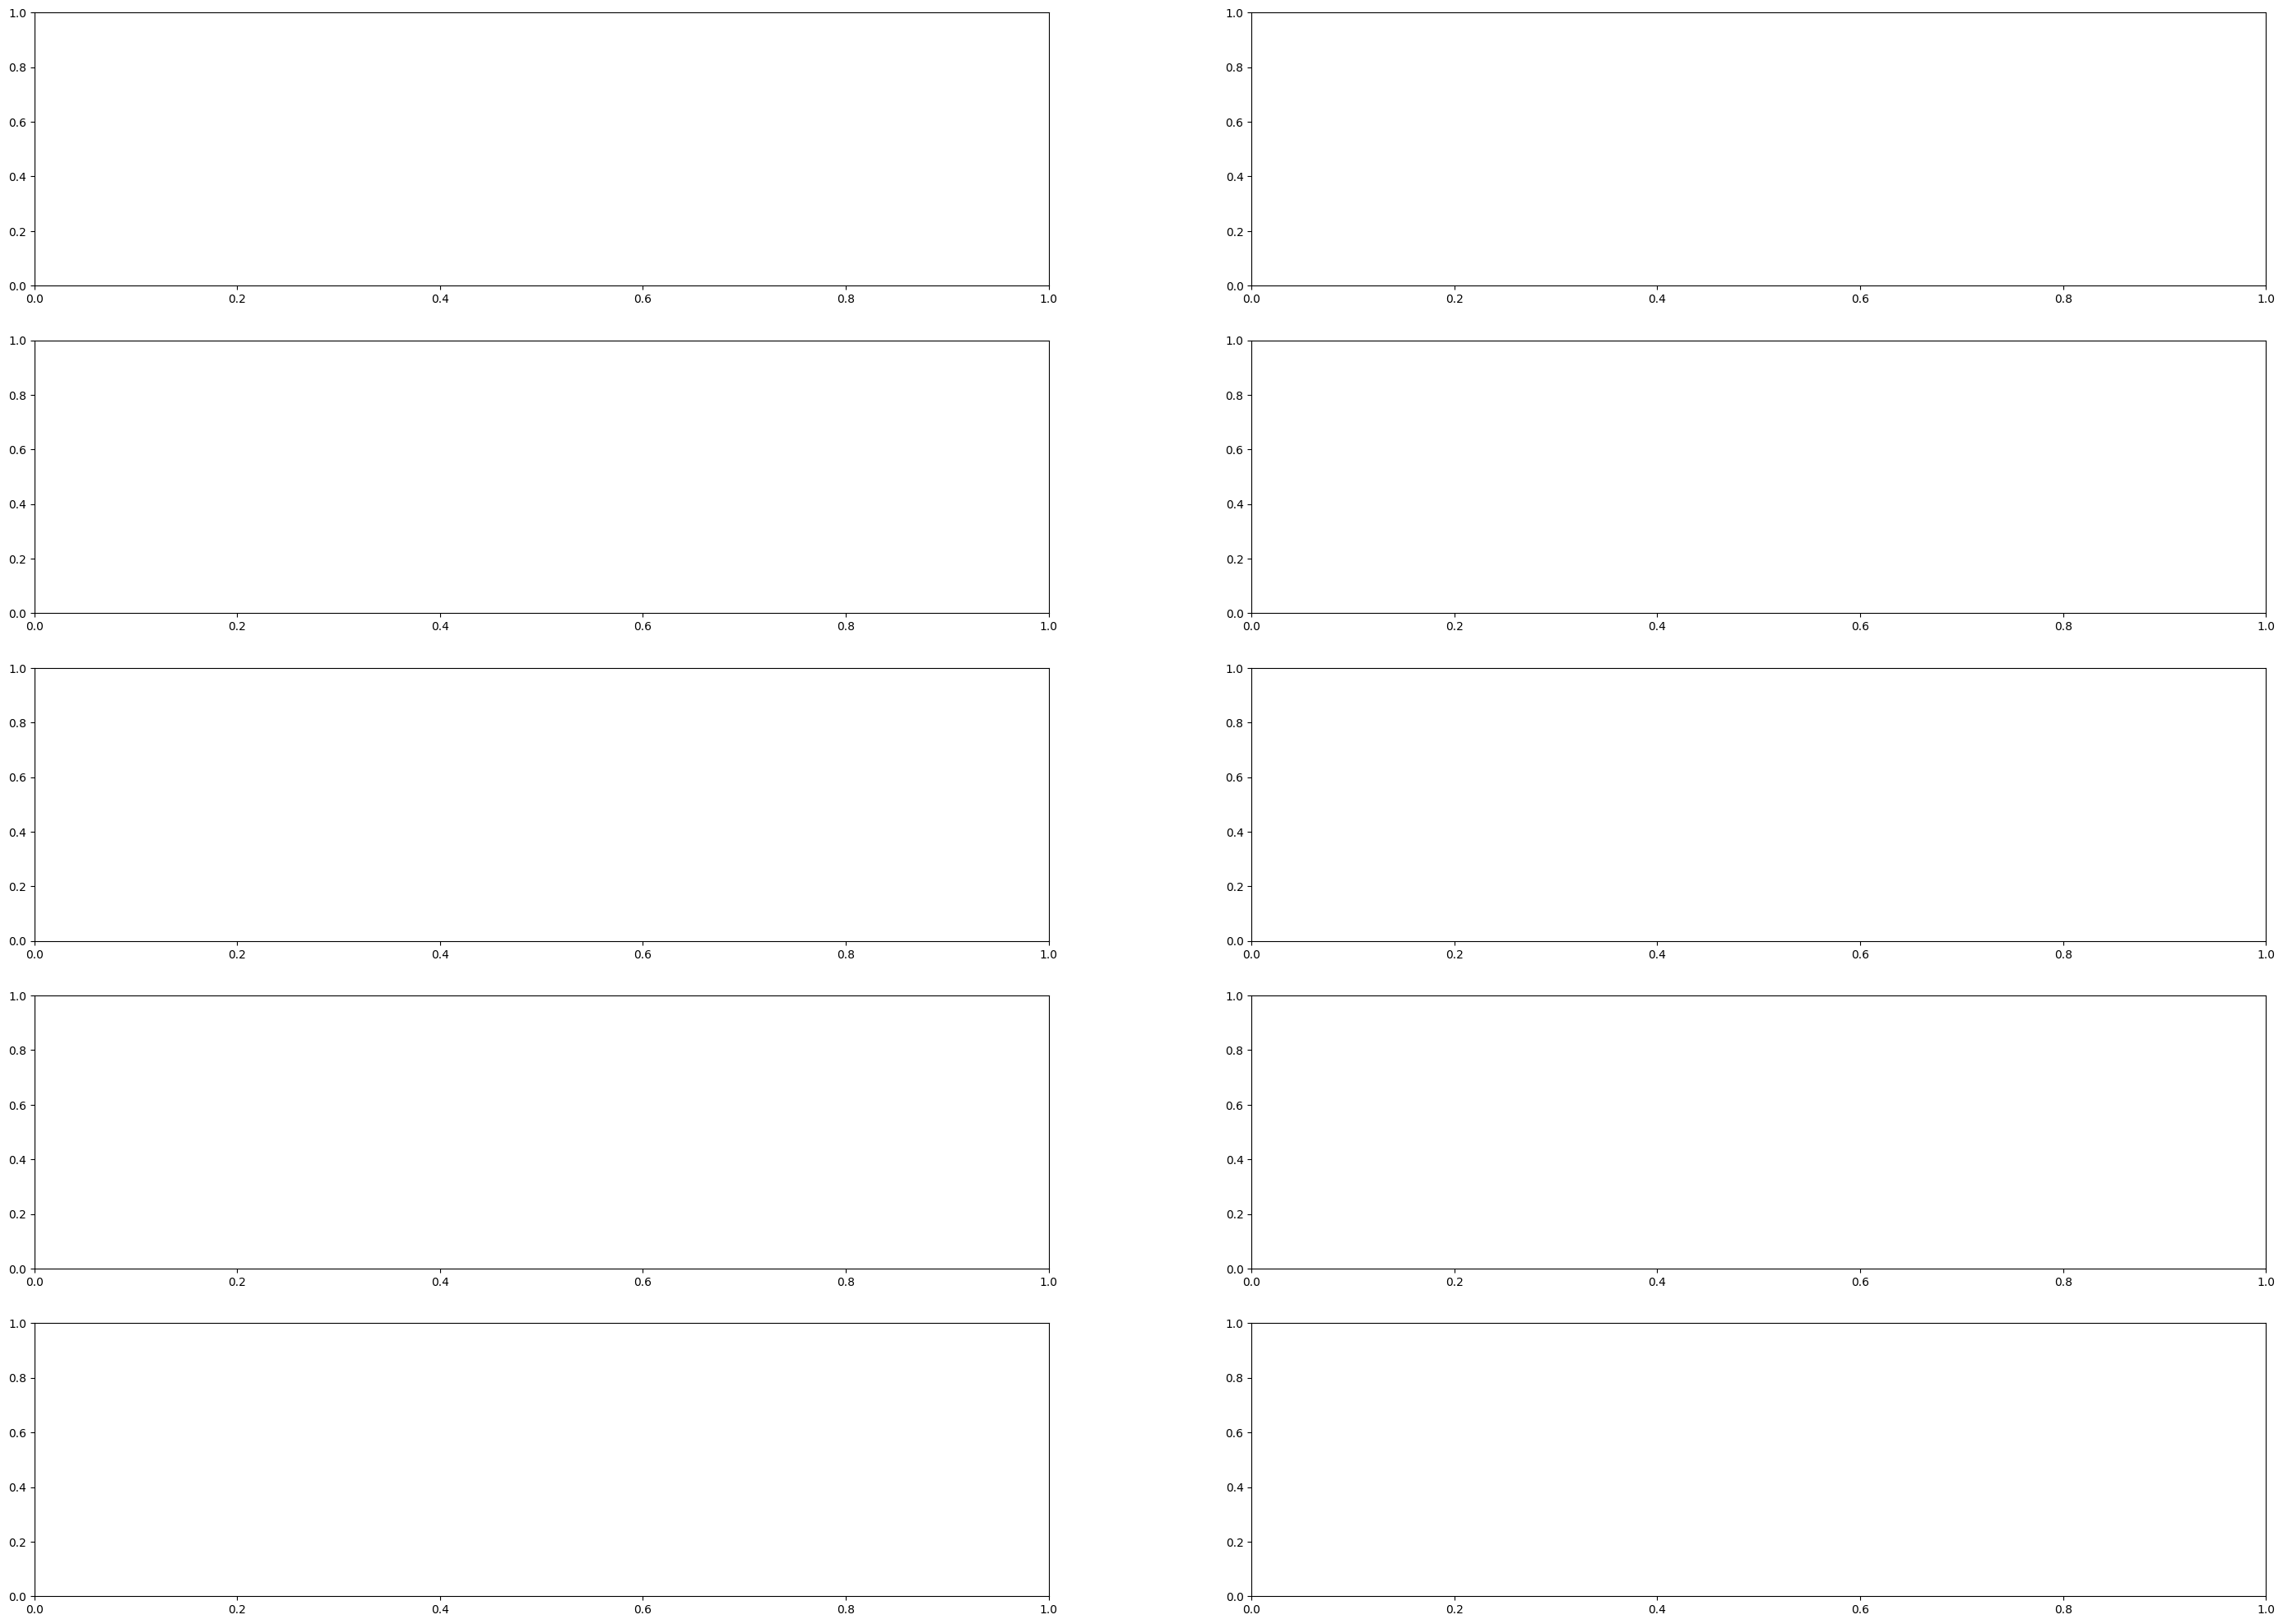

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size based on the number of columns
fig, axes = plt.subplots(nrows= 5, ncols=2, figsize=(35, 25))

# Plotting for Cluster Labels
for i, col in enumerate(['age','trestbps','chol','thalach','oldpeak'], 1):
    if col == 'cluster_labels':
        continue
    sns.boxplot(x =data_temp['cluster_labels'],y = data_temp[col],ax=axes[i-1,0])
    axes[i - 1, 0].set_title(f'Cluster Labels vs {col}')

# Plotting for Target Variable (Disease)
for i, col in enumerate(['age','trestbps','chol','thalach','oldpeak'], 1):
    if col == 'disease':
        continue
    sns.boxplot(x =data_1_temp['disease'],y = data_1_temp[col],ax=axes[i-1,1])
    axes[i -1, 1].set_title(f'Disease vs {col}')

plt.show()


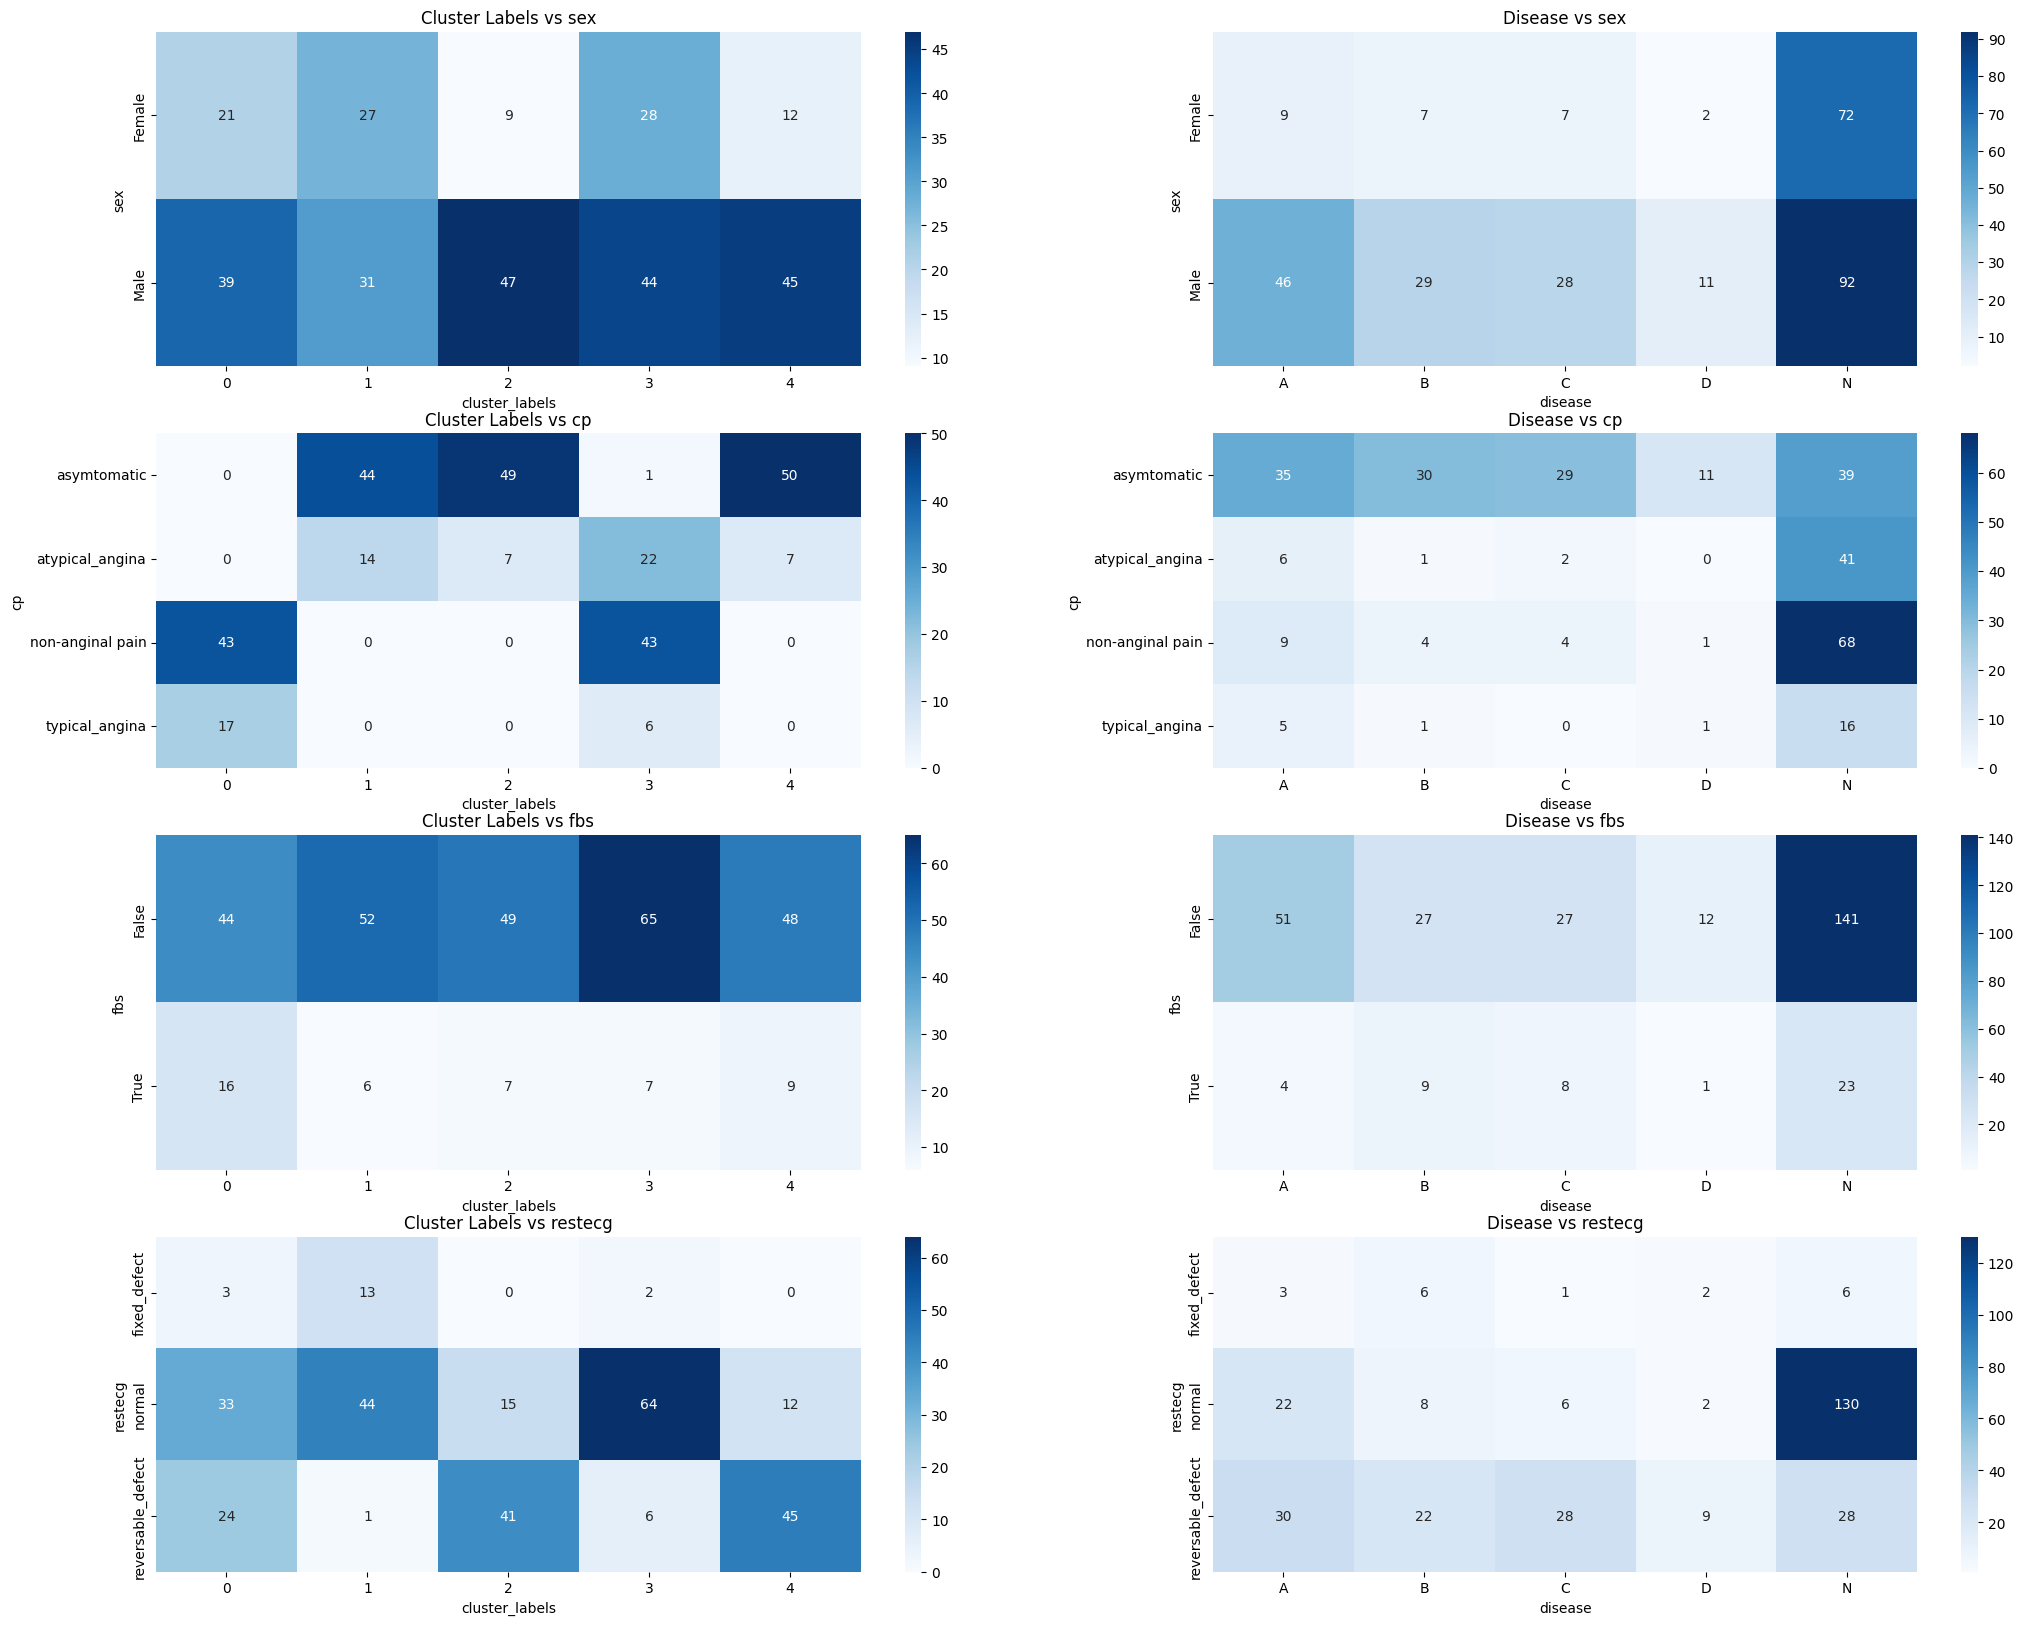

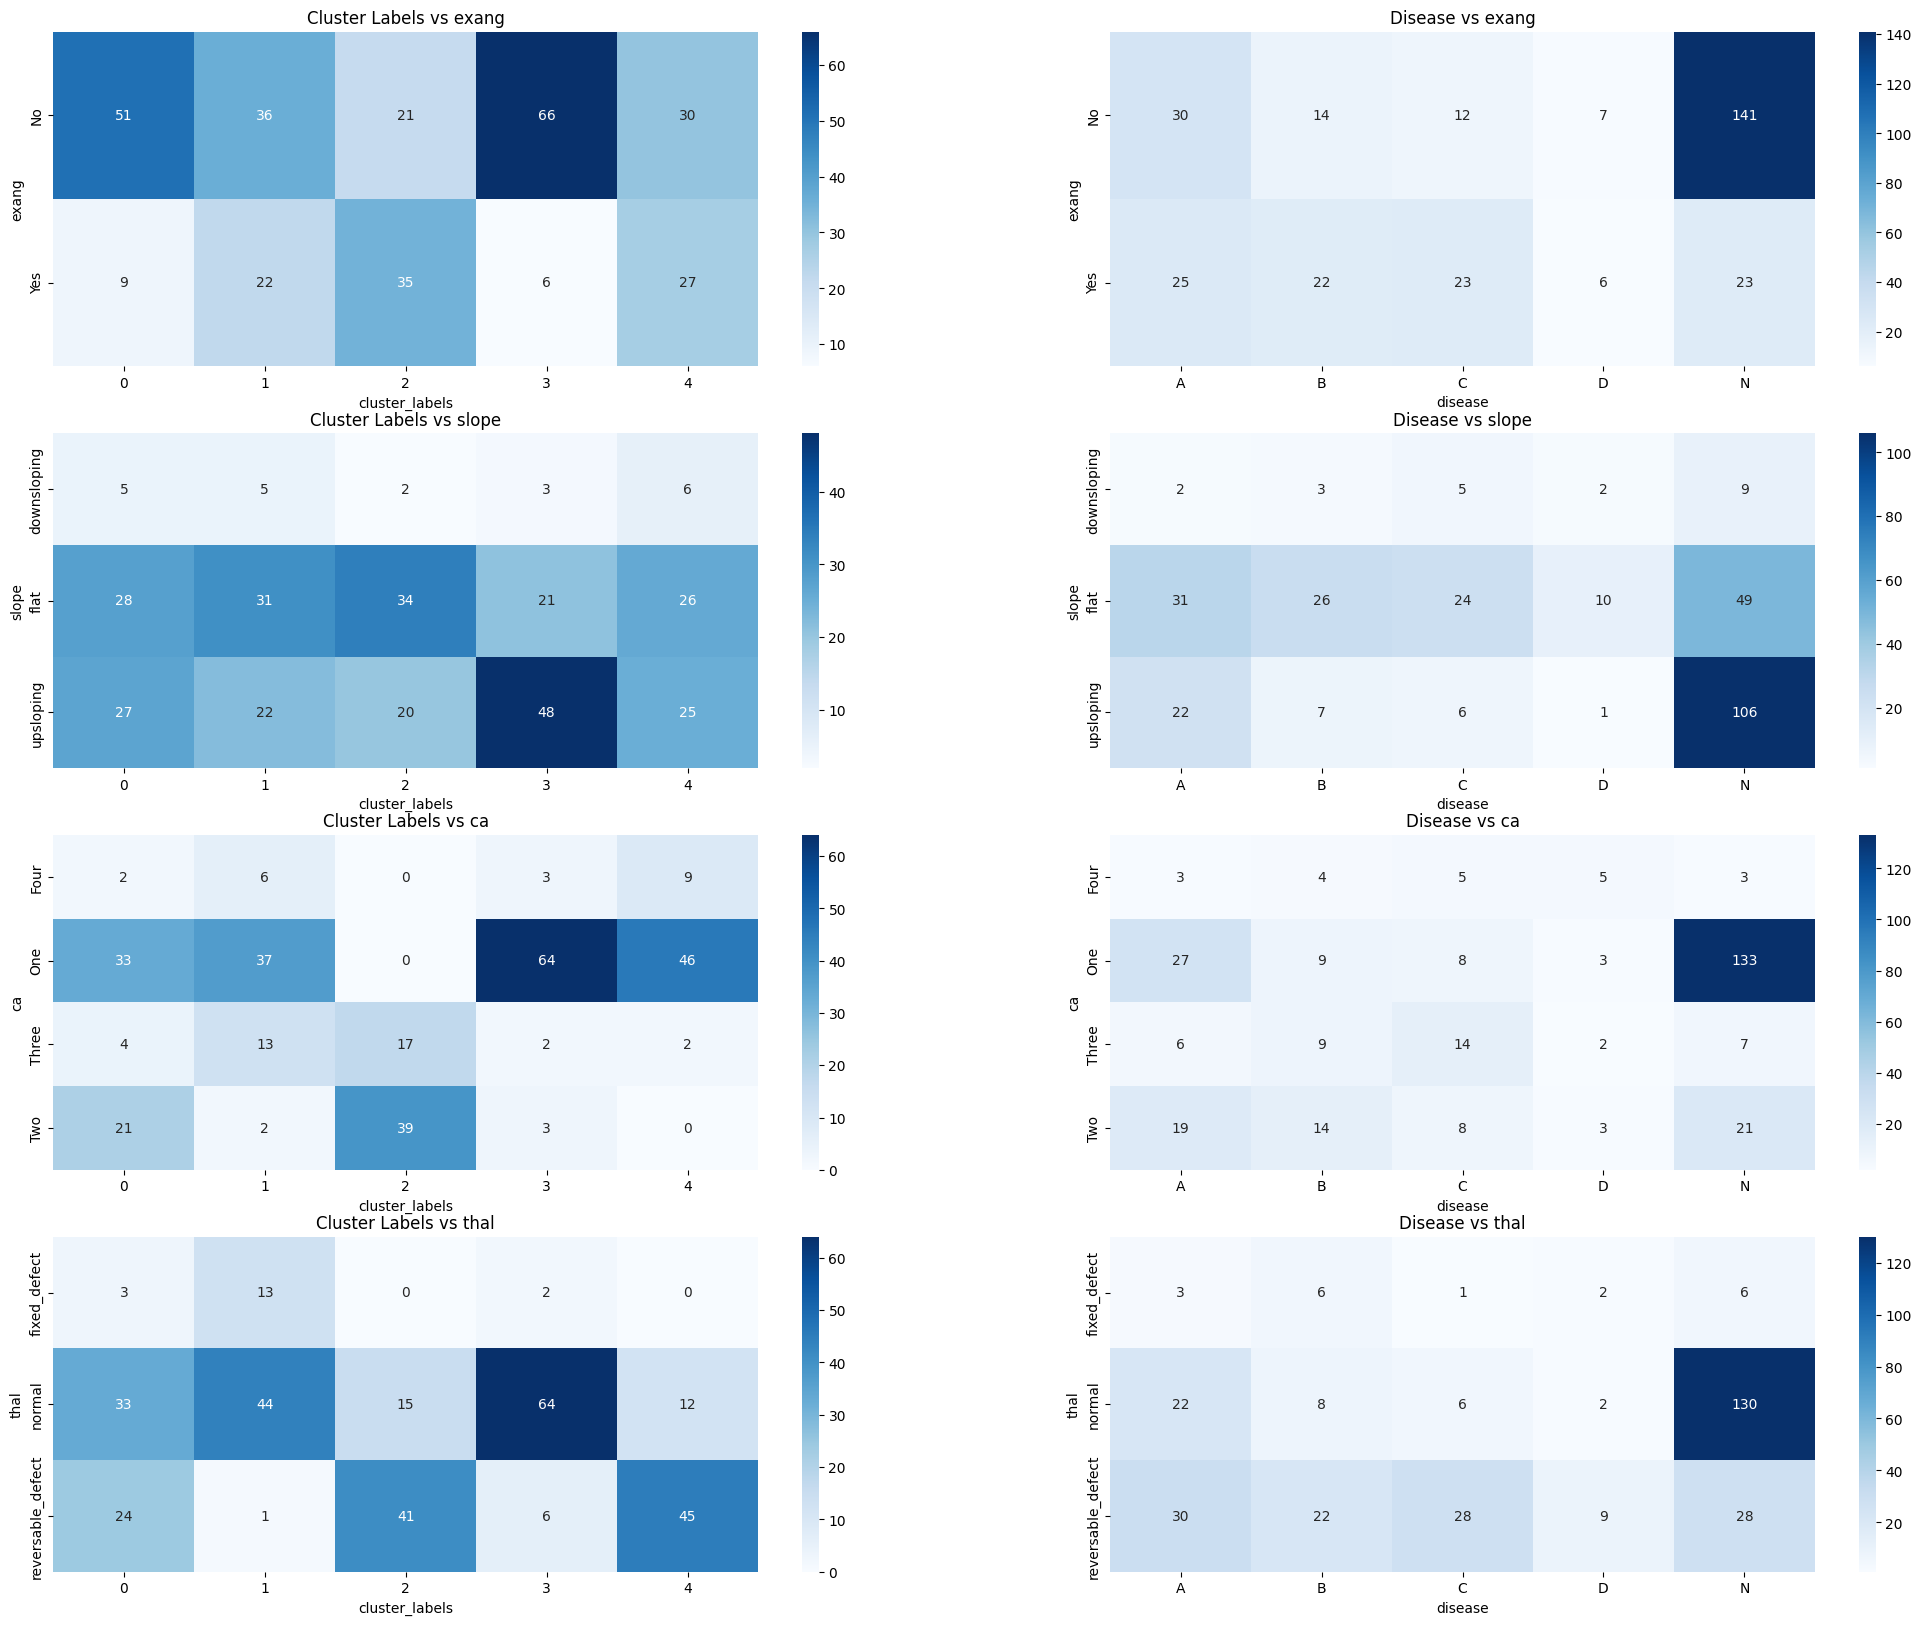

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size based on the number of columns
fig, axes = plt.subplots(nrows= 4, ncols=2, figsize=(25, 20))

# Plotting for Cluster Labels
for i, col in enumerate(['sex','cp','fbs','restecg'], 1):
    if col == 'cluster_labels':
        continue
    sns.heatmap(pd.crosstab(data_temp[col], data_temp['cluster_labels']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 0])
    axes[i - 1, 0].set_title(f'Cluster Labels vs {col}')

# Plotting for Target Variable (Disease)
for i, col in enumerate(['sex','cp','fbs','restecg'], 1):
    if col == 'disease':
        continue
    sns.heatmap(pd.crosstab(data_1_temp[col], data_1_temp['disease']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 1])
    axes[i -1, 1].set_title(f'Disease vs {col}')

plt.show()

fig, axes = plt.subplots(nrows= 4, ncols=2, figsize=(25, 20))

# Plotting for Cluster Labels
for i, col in enumerate(['exang','slope','ca','thal'], 1):
    if col == 'cluster_labels':
        continue
    sns.heatmap(pd.crosstab(data_temp[col], data_temp['cluster_labels']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 0])
    axes[i - 1, 0].set_title(f'Cluster Labels vs {col}')

# Plotting for Target Variable (Disease)
for i, col in enumerate(['exang','slope','ca','thal'], 1):
    if col == 'disease':
        continue
    sns.heatmap(pd.crosstab(data_1_temp[col], data_1_temp['disease']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 1])
    axes[i -1, 1].set_title(f'Disease vs {col}')

plt.show()

Conclude tommrow.

**Accuracy test**

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder
# Assuming 'data_temp' contains your data and 'cluster_labels' is the column with cluster assignments
data_for_silhouette = data_temp.drop('cluster_labels', axis=1)
data_for_silhouette_mean = data_mean.drop('cluster_labels_mean', axis=1)
data_for_silhouette_remove = data_remove.drop('cluster_labels_remove', axis=1)
# Label encode categorical variables
label_encoder = LabelEncoder()
for col in data_for_silhouette.select_dtypes(include='object'):
    data_for_silhouette[col] = label_encoder.fit_transform(data_for_silhouette[col])
    data_mean[col] = label_encoder.fit_transform(data_for_silhouette_mean[col])
    data_remove[col] = label_encoder.fit_transform(data_for_silhouette_remove[col])

# Calculate Silhouette Score
silhouette_avg = silhouette_score(data_for_silhouette, data_temp['cluster_labels'])

print("Silhouette Score: (Data Filled with Median)", silhouette_avg)

silhouette_avg_mean = silhouette_score(data_for_silhouette_mean, data_mean['cluster_labels_mean'])

print("Silhouette Score: (Data Filled with mean)", silhouette_avg_mean)

silhouette_avg_remove = silhouette_score(data_for_silhouette_remove, data_remove['cluster_labels_remove'])

print("Silhouette Score: (Data Filled with remove)", silhouette_avg_remove)


Silhouette Score: (Data Filled with Median) -0.02548218417025595
Silhouette Score: (Data Filled with mean) -0.024287188946500175
Silhouette Score: (Data Filled with remove) -0.05316166276261072


In [ ]:
inertia = k_means.inertia_
print(f"Inertia: {inertia}")


Inertia: 554.8920786668476


**Inertia: 554.89**

Inertia is a measure of how far the points within a cluster are from the cluster's centroid. A lower inertia is generally preferred, but the absolute value doesn't convey much information on its own. You would typically compare it to the inertia of alternative clusterings with different numbers of clusters.


**Silhouette Score: -0.03**

The Silhouette Score ranges from -1 to 1, where a higher value indicates better-defined clusters. In this case, the negative value (-0.03) suggests that the clusters are not well-separated, and there may be overlapping regions or points that are assigned to the wrong cluster.
Interpreting these metrics together:


While the Inertia provides an absolute measure of clustering quality (lower is better), the Silhouette Score offers insights into the separation and cohesion of clusters. A negative Silhouette Score suggests that the data points might be incorrectly assigned or that the clusters have a considerable overlap.

## Hierarchical clustering


Hierarchical clustering is a method of cluster analysis that builds a hierarchy of clusters. It can be visualized as a tree-like diagram called a dendrogram. The two main types of hierarchical clustering are agglomerative and divisive.

* Agglomerative Hierarchical Clustering: This starts with each data point as a separate cluster and merges the closest clusters iteratively until only one cluster remains.
* Divisive Hierarchical Clustering: This starts with all data points in one cluster and splits it recursively until each data point is in its own cluster.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

# Target = data_2['disease']
# data_3 = data_2.drop('disease',axis=1)
list_continous = list(data_1.select_dtypes('float64'))
list_continous.append('age')
# Create a ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal', OrdinalEncoder(), list_B),
        ('continuous', StandardScaler(), list_continous)
    ]
)
hierarchical = AgglomerativeClustering(n_clusters=5, linkage='ward')
hierarchical_mean = AgglomerativeClustering(n_clusters=5, linkage='ward')
hierarchical_remove = AgglomerativeClustering(n_clusters=5, linkage='ward')


# Create a Pipeline with the preprocessing steps and the logistic regression model
pipeline_1 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', hierarchical)
])


pipeline_mean = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', hierarchical_mean)
])

pipeline_remove = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', hierarchical_remove)
])

pipeline_1.fit(data_temp)

pipeline_mean.fit(data_mean)

pipeline_remove.fit(data_remove)

cluster_labels = pipeline_1.named_steps['classifier'].labels_
cluster_labels_mean = pipeline_mean.named_steps['classifier'].labels_
cluster_labels_remove = pipeline_remove.named_steps['classifier'].labels_

print(cluster_labels)



[0 4 4 3 3 1 4 1 2 1 4 1 0 0 0 0 3 1 0 1 0 0 1 0 2 0 0 0 1 1 0 2 0 1 3 1 1
 4 2 0 1 3 4 0 4 0 0 1 0 0 2 1 2 3 2 2 0 1 0 0 1 0 1 0 2 2 0 0 1 3 0 4 2 4
 2 0 2 0 1 1 1 1 3 0 1 3 0 0 1 0 4 1 0 3 0 2 2 2 2 1 1 3 2 0 0 0 2 0 2 1 1
 2 0 1 0 1 0 1 1 2 2 1 0 1 0 1 1 2 3 4 0 0 3 1 3 1 4 2 1 0 1 0 1 0 0 0 1 3
 3 0 0 1 0 2 4 4 1 2 2 0 0 4 0 4 0 1 0 2 1 1 0 1 4 4 4 2 1 4 0 0 1 2 0 0 4
 4 3 4 2 0 0 1 1 4 0 4 0 1 1 0 1 4 0 0 1 1 2 1 1 4 3 3 3 4 2 0 3 1 4 4 3 0
 3 2 4 3 1 0 2 4 0 1 0 0 0 1 1 1 1 3 3 3 1 0 0 4 2 2 2 1 4 2 2 0 1 3 4 0 4
 0 0 4 0 3 2 1 1 0 1 3 2 4 2 4 0 0 0 3 2 4 2 0 2 3 2 4 4 0 0 1 0 1 1 2 4 3
 4 1 3 4 2 2 3]


In [4]:
data_temp['cluster_labels'] = cluster_labels
data_mean['cluster_labels_mean'] = cluster_labels_mean
data_remove['cluster_labels_remove'] = cluster_labels_remove

sns.pairplot(data_temp, hue='cluster_labels',palette='Set1', markers='X')
plt.show()
sns.pairplot(data_1_temp, hue='disease', markers='X')
plt.show()


NameError: name 'cluster_labels' is not defined

NameError: name 'data_temp' is not defined

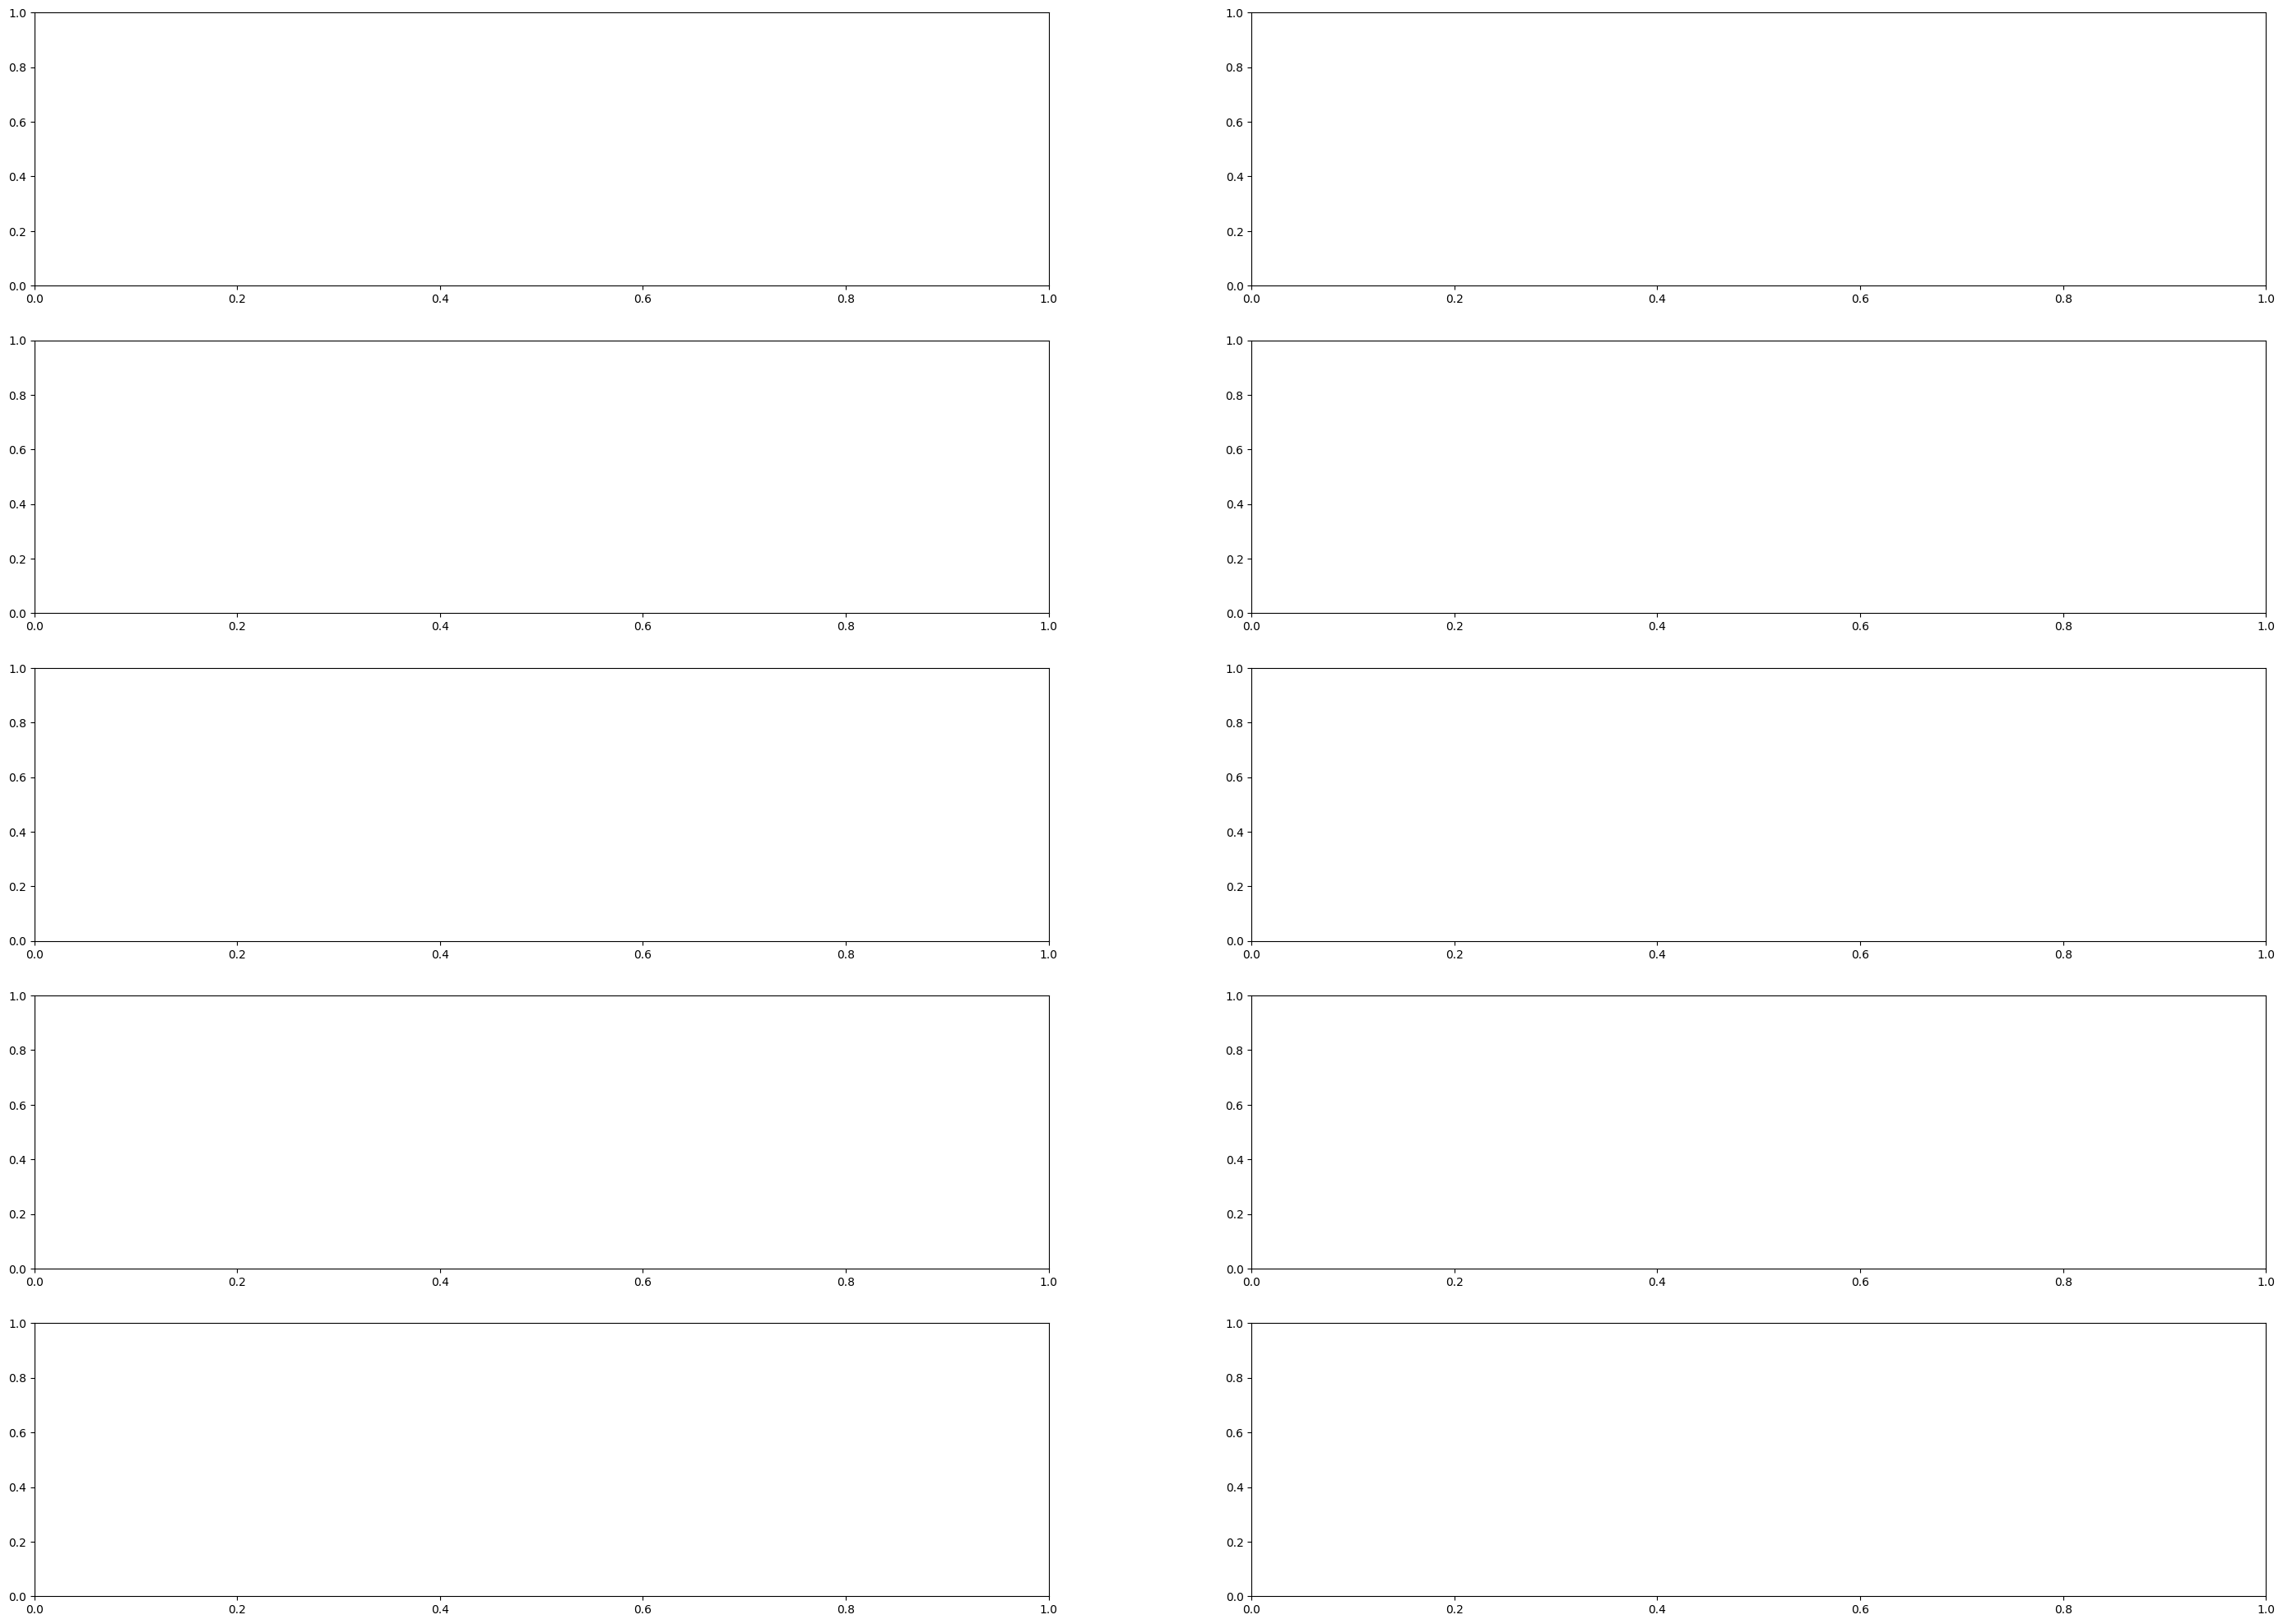

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size based on the number of columns
fig, axes = plt.subplots(nrows= 5, ncols=2, figsize=(35, 25))

# Plotting for Cluster Labels
for i, col in enumerate(['age','trestbps','chol','thalach','oldpeak'], 1):
    if col == 'cluster_labels':
        continue
    sns.boxplot(x =data_temp['cluster_labels'],y = data_temp[col],ax=axes[i-1,0])
    axes[i - 1, 0].set_title(f'Cluster Labels vs {col}')

# Plotting for Target Variable (Disease)
for i, col in enumerate(['age','trestbps','chol','thalach','oldpeak'], 1):
    if col == 'disease':
        continue
    sns.boxplot(x =data_1_temp['disease'],y = data_1_temp[col],ax=axes[i-1,1])
    axes[i -1, 1].set_title(f'Disease vs {col}')

plt.show()


NameError: name 'pd' is not defined

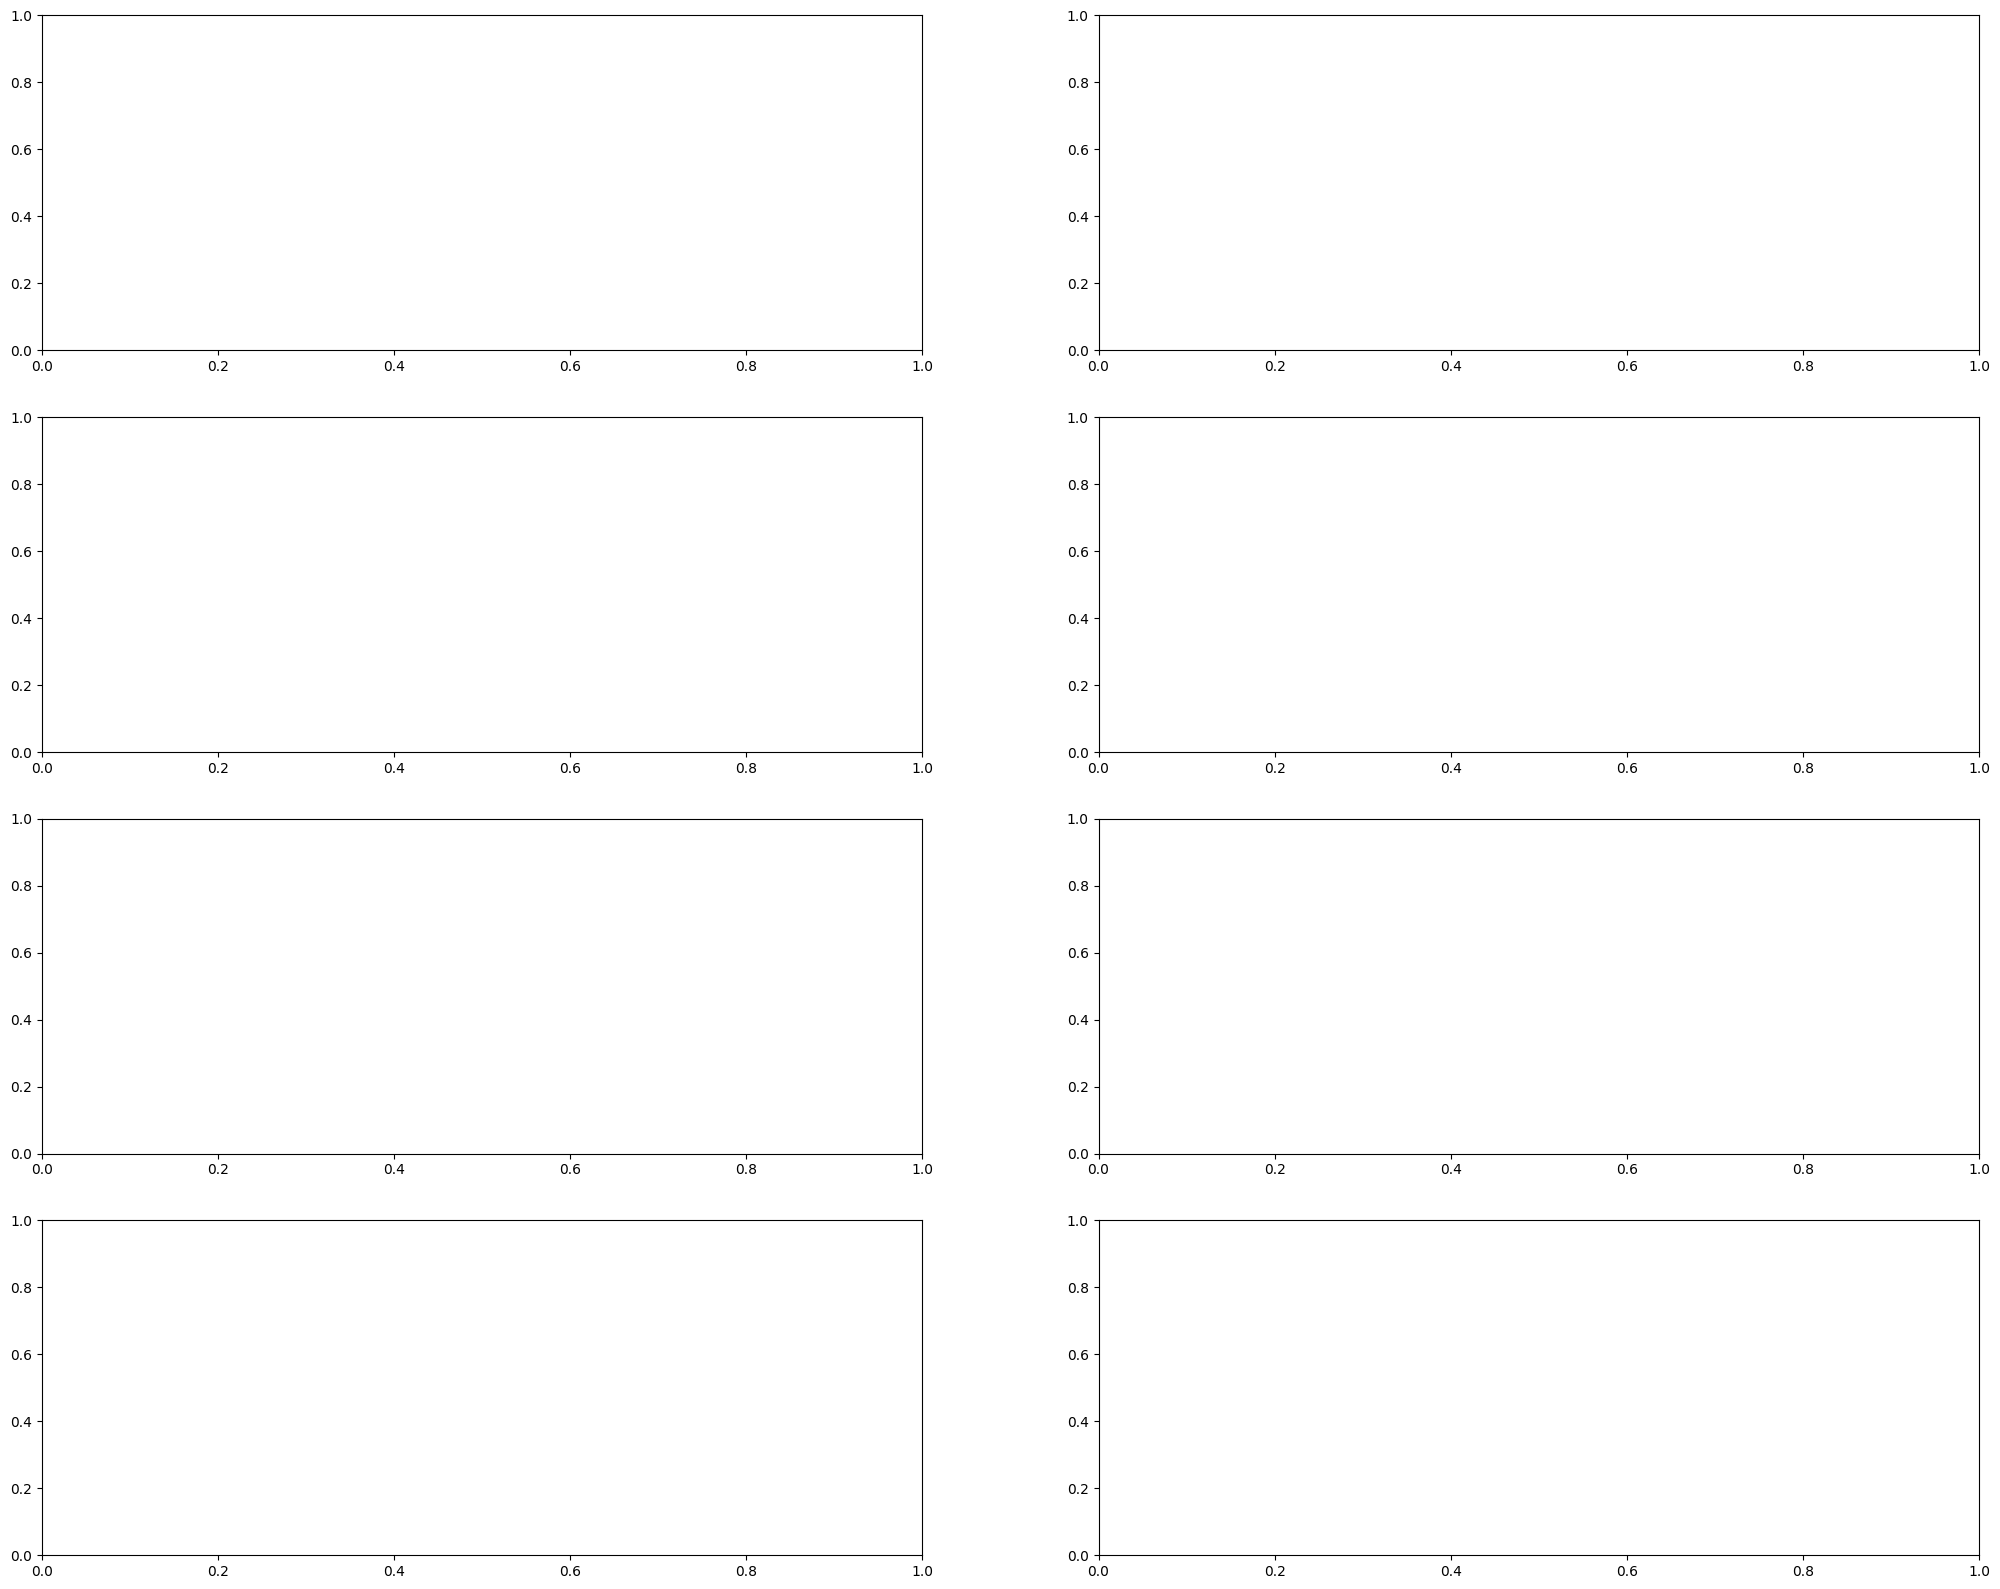

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size based on the number of columns
fig, axes = plt.subplots(nrows= 4, ncols=2, figsize=(25, 20))

# Plotting for Cluster Labels
for i, col in enumerate(['sex','cp','fbs','restecg'], 1):
    if col == 'cluster_labels':
        continue
    sns.heatmap(pd.crosstab(data_temp[col], data_temp['cluster_labels']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 0])
    axes[i - 1, 0].set_title(f'Cluster Labels vs {col}')

# Plotting for Target Variable (Disease)
for i, col in enumerate(['sex','cp','fbs','restecg'], 1):
    if col == 'disease':
        continue
    sns.heatmap(pd.crosstab(data_1_temp[col], data_1_temp['disease']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 1])
    axes[i -1, 1].set_title(f'Disease vs {col}')

plt.show()

fig, axes = plt.subplots(nrows= 4, ncols=2, figsize=(25, 20))

# Plotting for Cluster Labels
for i, col in enumerate(['exang','slope','ca','thal'], 1):
    if col == 'cluster_labels':
        continue
    sns.heatmap(pd.crosstab(data_temp[col], data_temp['cluster_labels']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 0])
    axes[i - 1, 0].set_title(f'Cluster Labels vs {col}')

# Plotting for Target Variable (Disease)
for i, col in enumerate(['exang','slope','ca','thal'], 1):
    if col == 'disease':
        continue
    sns.heatmap(pd.crosstab(data_1_temp[col], data_1_temp['disease']), annot=True, fmt="d", cmap="Blues", cbar=True, ax=axes[ i - 1 , 1])
    axes[i -1, 1].set_title(f'Disease vs {col}')

plt.show()

Conclude tommrow.

**Accuracy test**

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder
# Assuming 'data_temp' contains your data and 'cluster_labels' is the column with cluster assignments
data_for_silhouette = data_temp.drop('cluster_labels', axis=1)
data_for_silhouette_mean = data_mean.drop('cluster_labels_mean', axis=1)
data_for_silhouette_remove = data_remove.drop('cluster_labels_remove', axis=1)
# Label encode categorical variables
label_encoder = LabelEncoder()
for col in data_for_silhouette.select_dtypes(include='object'):
    data_for_silhouette[col] = label_encoder.fit_transform(data_for_silhouette[col])
    data_mean[col] = label_encoder.fit_transform(data_for_silhouette_mean[col])
    data_remove[col] = label_encoder.fit_transform(data_for_silhouette_remove[col])

# Calculate Silhouette Score
silhouette_avg = silhouette_score(data_for_silhouette, data_temp['cluster_labels'])

print("Silhouette Score: (Data Filled with Median)", silhouette_avg)

silhouette_avg_mean = silhouette_score(data_for_silhouette_mean, data_mean['cluster_labels_mean'])

print("Silhouette Score: (Data Filled with mean)", silhouette_avg_mean)

silhouette_avg_remove = silhouette_score(data_for_silhouette_remove, data_remove['cluster_labels_remove'])

print("Silhouette Score: (Data Filled with remove)", silhouette_avg_remove)

Silhouette Score: (Data Filled with Median) -0.04510031035005892
Silhouette Score: (Data Filled with mean) -0.06574443735849954
Silhouette Score: (Data Filled with remove) -0.05596815839338941


Silhouette Score: -0.04
suggest that this methods is better then kmeans with k = 5 but still there is room to improvement.

## DBSCAN

DBSCAN, which stands for Density-Based Spatial Clustering of Applications with Noise, is a clustering algorithm that groups together data points based on their density in the feature space. Unlike methods such as K-Means, DBSCAN does not assume that clusters have a spherical shape and can identify clusters with irregular shapes. Here are the key concepts of DBSCAN:

**Core Points:**

A data point is considered a core point if there are at least min_samples data points (including itself) within a distance of eps (epsilon) from it.
Core points are at the heart of clusters.
Border Points:

A data point is considered a border point if it is within eps distance from a core point but does not have enough neighbors to be a core point itself.
Border points are part of a cluster but not at its core.
Noise Points (Outliers):

Data points that are neither core points nor border points are considered noise points or outliers.
These points do not belong to any cluster.
Density-Reachability:

Two points are density-reachable if there is a chain of core points connecting them, with each pair of consecutive points being within eps distance of each other.
This concept allows DBSCAN to connect clusters of varying shapes and sizes.
Clustering Process:

The algorithm starts by selecting an arbitrary point. If the point is a core point, it forms a cluster by recursively adding all points density-reachable from it.
If the point is a border point, it is assigned to the cluster of a nearby core point.
The process continues until all points are visited and assigned to clusters or marked as noise.
Parameters:

* **eps:** The maximum distance between two samples for one to be considered as part of the neighborhood of the other.

min_samples: The number of samples (or total weight) in a neighborhood for a point to be considered a core point.
DBSCAN is particularly useful for discovering clusters in data with varying densities and irregular shapes. It is less sensitive to the initial configuration of points and can identify noise or outliers. However, choosing appropriate values for `eps` and `min_samples` is crucial for the algorithm's performance on a specific dataset.

**Knee Point in K-Distance Graph:**

Compute the distance to the k-th nearest neighbor for each data point. Plotting these distances can help you identify a "knee" point, where the rate of change in distance slows down. This knee point can be a good estimate for eps.

* Compute the distance to the k-th nearest neighbor for each data point.
* Sort the distances in ascending order.
* Plot the sorted distances.
* Observe the graph for a "knee" point, where the rate of change in distance slows down.

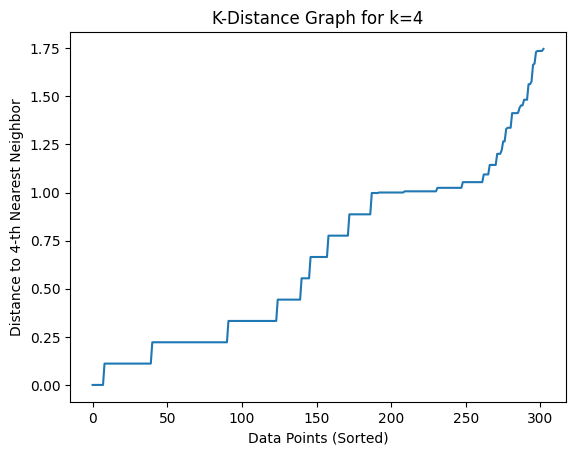

In [ ]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

list_continous = list(data_1.select_dtypes('float64'))
list_continous.append('age')
# Create a ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal', OrdinalEncoder(), list_B),
        ('continuous', StandardScaler(), list_continous)
    ]
)
pipeline_1 = Pipeline([
    ('preprocessor',preprocessor)
    ])

X_transformed = pipeline_1.fit_transform(data_1_temp)

# Choose the value of k for the k-distance graph
k = 4

# Compute the distance to the k-th nearest neighbor for each data point
neigh = NearestNeighbors(n_neighbors=k)
distances, _ = neigh.fit(X_transformed).kneighbors(X_transformed)
# Sort the distances
sorted_distances = np.sort(distances[:, -1])

# Plot the k-distance graph
plt.plot(sorted_distances)
plt.title(f'K-Distance Graph for k={k}')
plt.xlabel('Data Points (Sorted)')
plt.ylabel(f'Distance to {k}-th Nearest Neighbor')
plt.show()


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

# Target = data_2['disease']
# data_3 = data_2.drop('disease',axis=1)
list_continous = list(data_1.select_dtypes('float64'))
list_continous.append('age')
# Create a ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('ordinal', OrdinalEncoder(), list_B),
        ('continuous', StandardScaler(), list_continous)
    ]
)
DBscan = DBSCAN(eps=1.1, min_samples=5)
DBscan_mean = DBSCAN(eps=1.1, min_samples=5)
DBscan_remove = DBSCAN(eps=1.1, min_samples=5)


# Create a Pipeline with the preprocessing steps and the logistic regression model
pipeline_1 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DBscan)
])


pipeline_mean = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DBscan_mean)
])

pipeline_remove = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DBscan_remove)
])

pipeline_1.fit(data_temp)

pipeline_mean.fit(data_mean)

pipeline_remove.fit(data_remove)

cluster_labels = pipeline_1.named_steps['classifier'].labels_
cluster_labels_mean = pipeline_mean.named_steps['classifier'].labels_
cluster_labels_remove = pipeline_remove.named_steps['classifier'].labels_

print(cluster_labels)



[-1  0  1  0  0  0  0  0  1  1  2  0 -1  1  1  0 -1  0  0  0  0  0  0  1
  1  0  0  0  0  1 -1  1  0  1  0  0  1  2  1  0  1 -1  0  0  0  1  0  1
  0  0  0  1  0  0  1  1  1  1 -1  0  1  0  1  0  1  1  0  1  1  0  0  1
  1 -1  0  0  1  0  0  1  0  0  0  1  0  0  0  0  0  0  0  1  1  0  0  1
  1  1  0  0  0  0  0  0 -1  1  1  1  1  1  1  0 -1  1  1 -1  0  0  1  1
  1  1  0  1  0  0  1  1  0  0  1  1  0  0  0  0 -1  1  1  0  0  1  0  1
  1  0  1  0  0  0  1  0  1  1  0  0  1  1  1 -1  1 -1  0  0  0  1  0  0
  1  0  1  1  0  0  2  1  1  2  0  0  1  1 -1  1  0  0 -1 -1  1  1  0  1
  1  0  0  0  0  0  0  0  0  0  1  1  1  1  1  1  0  0  0 -1  0  1  0  1
  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  1  1  0  0
  0  0  0  0  0  0  1  0  1  0  2  1  1  0  0  0  0  0  0  1 -1  0  0  0
  0 -1  0 -1  1  0  1 -1  1  0  0  1  0  0  0  0  1  0  1  0  1 -1  2  1
  1  0  1  0 -1  1  0  0  2  1  1  1  1  0  0]


Conclude tommrow.

**Accuracy test**

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder
# Assuming 'data_temp' contains your data and 'cluster_labels' is the column with cluster assignments
data_for_silhouette = data_temp.drop('cluster_labels', axis=1)
data_for_silhouette_mean = data_mean.drop('cluster_labels_mean', axis=1)
data_for_silhouette_remove = data_remove.drop('cluster_labels_remove', axis=1)

# Label encode categorical variables
label_encoder = LabelEncoder()
for col in data_for_silhouette.select_dtypes(include='object'):
    data_for_silhouette[col] = label_encoder.fit_transform(data_for_silhouette[col])
    data_mean[col] = label_encoder.fit_transform(data_for_silhouette_mean[col])
    data_remove[col] = label_encoder.fit_transform(data_for_silhouette_remove[col])

# Calculate Silhouette Score
silhouette_avg = silhouette_score(data_for_silhouette, data_temp['cluster_labels'])

print("Silhouette Score: (Data Filled with Median)", silhouette_avg)

silhouette_avg_mean = silhouette_score(data_for_silhouette_mean, data_mean['cluster_labels_mean'])

print("Silhouette Score: (Data Filled with mean)", silhouette_avg)

silhouette_avg_remove = silhouette_score(data_for_silhouette_remove, data_remove['cluster_labels_remove'])

print("Silhouette Score: (Data Filled with remove)", silhouette_avg)


Silhouette Score: (Data Filled with Median) -0.0750880138552917
Silhouette Score: (Data Filled with mean) -0.0750880138552917
Silhouette Score: (Data Filled with remove) -0.0750880138552917


**Accuracy DBSCAN**
as we can see accuracy is `-.07` , that is hierarchical aggromerative is best way to cluster in this data , unless we change the k-means methods center points number .
